# 🏠 Apartment Hunter : estimation du prix d'un bien immobilier

*Projet La Plateforme, B3 IA*

## Contexte

Fixer le prix d'un bien immobilier est difficile : il dépend de nombreuses caractéristiques (surface, nombre de pièces, état, localisation, vue, année de construction…) qui interagissent entre elles. Une estimation trop haute fait traîner la vente, une estimation trop basse fait perdre de l'argent au vendeur.

Nous utilisons le jeu de données **King County House Sales** (`kc_house_data.csv`) : **21 613 ventes** de maisons dans le comté de King (région de Seattle, États-Unis) entre mai 2014 et mai 2015. Chaque ligne décrit une maison vendue et son prix de vente (`price`), qui sera notre **variable cible**.

## Problématique

> **Peut-on estimer le prix d'un bien immobilier à partir de ses caractéristiques ?**

Il s'agit d'un problème de **régression supervisée** : prédire une valeur continue (le prix) à partir de variables explicatives. L'objectif final est de livrer un modèle exploitable via une application web Flask, dans laquelle un utilisateur saisit les caractéristiques d'un bien et obtient une estimation de son prix.

## Plan du notebook

0. **Imports et versions** : bibliothèques utilisées, versions affichées pour la reproductibilité
1. **Chargement et nettoyage** : corrections d'erreurs évidentes, création de variables, choix de la cible
2. **Séparation train / test** : effectuée *avant* tout traitement qui apprend des données, afin d'éviter toute fuite d'information (*data leakage*)
3. **Sélection de features** : Boruta, puis *forward feature selection*
4. **Entraînement et comparaison de modèles** : régression linéaire / Ridge, Random Forest, Gradient Boosting, évalués avec MAE, RMSE et R²
5. **Optimisation par Grid Search** du meilleur modèle
6. **Évaluation finale sur le jeu de test et sauvegarde** du modèle avec `joblib`
7. **Conclusion** : réponse à la problématique, limites et pistes d'amélioration

> Pour la reproductibilité, toutes les opérations aléatoires utilisent `random_state=42`.

## 0. Imports et versions

On importe ici toutes les bibliothèques du notebook, regroupées par usage. Afficher leurs versions permet de reproduire exactement les résultats : un changement de version de scikit-learn, par exemple, peut modifier légèrement un modèle. Ces versions correspondent à celles figées dans `requirements.txt`.

In [1]:
# --- Bibliothèques standard ---
import io
import json
import platform
import sys
import time
from datetime import datetime
import warnings
from importlib.metadata import version

# --- Manipulation des données ---
import numpy as np
import pandas as pd

# --- Visualisation ---
import matplotlib.pyplot as plt
import seaborn as sns

# --- Préparation des données et validation ---
from sklearn.model_selection import train_test_split, GridSearchCV, KFold, cross_val_score, cross_val_predict
from sklearn.preprocessing import StandardScaler, TargetEncoder
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# --- Sélection de features ---
from boruta import BorutaPy
from sklearn.feature_selection import SequentialFeatureSelector

# --- Modèles de régression ---
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor, HistGradientBoostingRegressor

# --- Métriques d'évaluation ---
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# --- Sauvegarde du modèle ---
import joblib

# Graine aléatoire unique, réutilisée partout pour la reproductibilité
RANDOM_STATE = 42

# Options d'affichage : toutes les colonnes visibles, style graphique homogène
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

# Affichage des versions (lues depuis les métadonnées des paquets installés)
print(f"Python       : {sys.version.split()[0]}")
for paquet in ["pandas", "numpy", "matplotlib", "seaborn", "scikit-learn", "Boruta", "joblib"]:
    print(f"{paquet:<13}: {version(paquet)}")

Python       : 3.13.1
pandas       : 3.0.6
numpy        : 2.5.4
matplotlib   : 3.11.2
seaborn      : 0.13.2
scikit-learn : 1.9.1
Boruta       : 0.4.3
joblib       : 1.6.0


## 1. Chargement et nettoyage

On part du **dataset brut** `data/raw/kc_house_data.csv`. On n'utilise pas la version Excel retravaillée pour Power BI : elle contient des colonnes dérivées du prix, qui donneraient la réponse au modèle (fuite de la cible), et on veut que chaque transformation soit tracée et justifiée dans ce notebook.

**Ce qui peut se faire avant le split train/test, et ce qui ne le peut pas :**

| Avant le split (sur tout le dataset) | Après le split (ajusté sur le train uniquement) |
|---|---|
| Corriger une faute de saisie évidente | Imputation (moyenne, médiane…) |
| Supprimer une ligne physiquement impossible | Mise à l'échelle (`StandardScaler`…) |
| Créer une variable par une règle fixe (ex. `house_age = sale_year - yr_built`) | Encodage qui dépend des données (one-hot sur les catégories vues, *target encoding*) |
| Appliquer une fonction fixe (ex. `log1p`) | Sélection de features (Boruta, forward selection) |

La règle : un traitement de la colonne de gauche **n'apprend rien des données**. Il donne le même résultat pour une ligne, quelles que soient les autres lignes. Un traitement de la colonne de droite **calcule des statistiques** sur les données. Fait avant le split, il laisserait passer de l'information du jeu de test vers l'entraînement, et l'évaluation finale serait trop optimiste.

### 1.1 Chargement et premier aperçu

**Quoi :** on charge le CSV, puis on affiche ses dimensions, les types des colonnes, les premières lignes, les valeurs manquantes et les lignes en double.

**Pourquoi :** avant toute transformation, il faut vérifier que le fichier est bien lu (bons types, bon nombre de lignes) et repérer les problèmes de qualité qui guideront le nettoyage.

In [2]:
CHEMIN_BRUT = "../data/raw/kc_house_data.csv"
df = pd.read_csv(CHEMIN_BRUT)

print(f"Dimensions : {df.shape[0]} lignes x {df.shape[1]} colonnes\n")
print("Types des colonnes :")
print(df.dtypes)

display(df.head())

print(f"Valeurs manquantes (total) : {df.isna().sum().sum()}")
print(f"Lignes entièrement dupliquées : {df.duplicated().sum()}")

Dimensions : 21613 lignes x 21 colonnes

Types des colonnes :
id                 int64
date                 str
price            float64
bedrooms           int64
bathrooms        float64
sqft_living        int64
sqft_lot           int64
floors           float64
waterfront         int64
view               int64
condition          int64
grade              int64
sqft_above         int64
sqft_basement      int64
yr_built           int64
yr_renovated       int64
zipcode            int64
lat              float64
long             float64
sqft_living15      int64
sqft_lot15         int64
dtype: object


,id,date,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_above,sqft_basement,yr_built,yr_renovated,zipcode,lat,long,sqft_living15,sqft_lot15
0,7129300520,20141013T000000,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,1180,0,1955,0,98178,47.5112,-122.257,1340,5650
1,6414100192,20141209T000000,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,2170,400,1951,1991,98125,47.7210,-122.319,1690,7639
2,5631500400,20150225T000000,180000.0,2,1.00,770,10000,1.0,0,0,3,6,770,0,1933,0,98028,47.7379,-122.233,2720,8062
3,2487200875,20141209T000000,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,1050,910,1965,0,98136,47.5208,-122.393,1360,5000
4,1954400510,20150218T000000,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,1680,0,1987,0,98074,47.6168,-122.045,1800,7503


Valeurs manquantes (total) : 0
Lignes entièrement dupliquées : 0


**Constat :** 21 613 lignes et 21 colonnes, aucune valeur manquante, aucune ligne entièrement dupliquée. Les types sont cohérents. Deux colonnes demandent une attention particulière :
- `date` est lue comme du texte (format `20141013T000000`) : on la convertira en date.
- `zipcode` est lu comme un entier, mais c'est un code postal, donc une catégorie et non une quantité (voir 1.9).

### 1.2 Doublons d'identifiant (`id`)

**Quoi :** on compte les `id` qui apparaissent plusieurs fois et on regarde un exemple.

**Pourquoi :** un même `id` sur plusieurs lignes peut signaler un vrai doublon (même ligne saisie deux fois, à supprimer) ou une même maison **vendue plusieurs fois** (deux ventes réelles, à garder). Il faut savoir lequel avant de décider.

In [3]:
occurrences = df["id"].value_counts()
ids_multiples = occurrences[occurrences > 1]

print(f"Nombre d'id apparaissant plusieurs fois : {len(ids_multiples)}")
print(f"Nombre de lignes concernées              : {ids_multiples.sum()}")
print(f"Nombre maximal de ventes pour un même id : {ids_multiples.max()}")
print(f"Doublons sur le couple (id, date)        : {df.duplicated(subset=['id', 'date']).sum()}")

# Exemple : une maison vendue plusieurs fois
exemple_id = ids_multiples.index[0]
display(df.loc[df["id"] == exemple_id, ["id", "date", "price", "bedrooms", "sqft_living", "yr_renovated"]])

Nombre d'id apparaissant plusieurs fois : 176
Nombre de lignes concernées              : 353
Nombre maximal de ventes pour un même id : 3
Doublons sur le couple (id, date)        : 0


,id,date,price,bedrooms,sqft_living,yr_renovated
17602,795000620,20140924T000000,115000.0,3,1080,0
17603,795000620,20141215T000000,124000.0,3,1080,0
17604,795000620,20150311T000000,157000.0,3,1080,0


**Décision : on garde ces lignes.** Aucun couple (`id`, `date`) n'est dupliqué : chaque ligne correspond à une **vente distincte** de la même maison à une date différente (revente). Le prix change souvent d'une vente à l'autre, ce qui reflète l'évolution du marché ou de la maison. Ce sont des observations légitimes, pas des erreurs de saisie.

> Limite à garder en tête : une même maison peut se retrouver à la fois dans le train et dans le test, ce qui rend la tâche un peu plus facile pour le modèle. L'effet est négligeable ici (353 lignes sur 21 613, soit 1,6 %).

### 1.3 Correction de la maison à 33 chambres

**Quoi :** une maison déclare 33 chambres. On la corrige en **3 chambres**.

**Pourquoi :** c'est une faute de saisie évidente (un « 3 » tapé deux fois). Sa surface habitable (1 620 sqft, soit environ 150 m²) avec 1,75 salle de bain correspond à une maison typique de 3 chambres. La surface médiane des maisons de 3 chambres est d'environ 1 680 sqft, alors que même les maisons de 10 chambres et plus font plus de 3 000 sqft. Corriger plutôt que supprimer garde une vente réelle et cohérente. Cette correction concerne une seule ligne et n'utilise aucune statistique apprise sur les données : elle peut se faire avant le split.

In [4]:
masque_33 = df["bedrooms"] == 33
assert masque_33.sum() == 1, "On attend exactement une maison à 33 chambres"
index_33 = df.index[masque_33][0]
colonnes_affichees = ["id", "price", "bedrooms", "bathrooms", "sqft_living", "sqft_lot", "floors"]

print("Surface habitable médiane selon le nombre de chambres (pour comparaison) :")
print(df.groupby("bedrooms")["sqft_living"].median().loc[[2, 3, 4, 5, 10, 11]].to_string())

print("\nAVANT correction :")
display(df.loc[[index_33], colonnes_affichees])

df.loc[index_33, "bedrooms"] = 3

print("APRÈS correction :")
display(df.loc[[index_33], colonnes_affichees])

Surface habitable médiane selon le nombre de chambres (pour comparaison) :
bedrooms
2     1140.0
3     1680.0
4     2410.0
5     2870.0
10    3610.0
11    3000.0

AVANT correction :


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors
15870,2402100895,640000.0,33,1.75,1620,6000,1.0


APRÈS correction :


,id,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors
15870,2402100895,640000.0,3,1.75,1620,6000,1.0


### 1.4 Suppression des maisons sans chambre ou sans salle de bain

**Quoi :** on supprime les lignes où `bedrooms == 0` ou `bathrooms == 0`.

**Pourquoi :** une maison vendue comme habitation avec 0 chambre ou 0 salle de bain est incohérente. Il s'agit probablement d'une erreur de saisie ou d'un bien atypique (terrain, local non résidentiel). Contrairement au cas précédent, on ne peut pas deviner la bonne valeur, donc on supprime ces lignes. Elles sont très peu nombreuses, donc on perd très peu d'information. Supprimer une ligne selon une règle fixe n'apprend rien des données : cela peut se faire avant le split.

In [5]:
masque_incoherent = (df["bedrooms"] == 0) | (df["bathrooms"] == 0)
print(f"Maisons avec 0 chambre      : {(df['bedrooms'] == 0).sum()}")
print(f"Maisons avec 0 salle de bain : {(df['bathrooms'] == 0).sum()}")

display(df.loc[masque_incoherent, ["id", "price", "bedrooms", "bathrooms", "sqft_living"]])

nb_avant = len(df)
df = df.loc[~masque_incoherent].reset_index(drop=True)
print(f"Lignes supprimées : {nb_avant - len(df)}  ({nb_avant} -> {len(df)} lignes)")

Maisons avec 0 chambre      : 13
Maisons avec 0 salle de bain : 10


,id,price,bedrooms,bathrooms,sqft_living
875,6306400140,1095000.0,0,0.00,3064
1149,3421079032,75000.0,1,0.00,670
3119,3918400017,380000.0,0,0.00,1470
3467,1453602309,288000.0,0,1.50,1430
4868,6896300380,228000.0,0,1.00,390
5832,5702500050,280000.0,1,0.00,600
6994,2954400190,1295650.0,0,0.00,4810
8477,2569500210,339950.0,0,2.50,2290
8484,2310060040,240000.0,0,2.50,1810
9773,3374500520,355000.0,0,0.00,2460


Lignes supprimées : 16  (21613 -> 21597 lignes)


### 1.5 Création de variables (*feature engineering*)

**Quoi et pourquoi, variable par variable :**

- **`sale_year` et `sale_month`** (extraites de `date`, qui est ensuite supprimée) : les modèles ne savent pas exploiter une chaîne de caractères comme `20141013T000000`. L'année capte l'évolution générale du marché entre 2014 et 2015. Le mois capte une éventuelle **saisonnalité**, car le marché immobilier est plus actif au printemps et en été.
- **`house_age = sale_year - yr_built`** : l'âge de la maison **au moment de la vente** est plus parlant que son année de construction. `yr_built` devient alors redondante : on la supprimera en 1.7.
- **`renovated`** (1 si `yr_renovated > 0`, sinon 0), puis suppression de `yr_renovated` : dans cette colonne, `0` ne veut pas dire « l'an 0 » mais « jamais rénovée ». Laissée telle quelle, elle placerait les maisons non rénovées 2 000 ans avant les autres, ce qui fausserait tout modèle linéaire. Un indicateur binaire représente correctement l'information.
- **`has_basement`** (1 si `sqft_basement > 0`, sinon 0) : avoir un sous-sol ou non est une information distincte de sa surface, et elle est plus simple à exploiter pour certains modèles.

Toutes ces variables sont calculées ligne par ligne avec une règle fixe, sans statistique apprise : aucun risque de fuite.

In [6]:
# Date de vente : conversion puis extraction de l'année et du mois
df["date"] = pd.to_datetime(df["date"], format="%Y%m%dT%H%M%S")
df["sale_year"] = df["date"].dt.year
df["sale_month"] = df["date"].dt.month
df = df.drop(columns="date")

# Âge de la maison au moment de la vente
df["house_age"] = df["sale_year"] - df["yr_built"]

# Indicateur de rénovation (0 dans yr_renovated = jamais rénovée)
df["renovated"] = (df["yr_renovated"] > 0).astype(int)
df = df.drop(columns="yr_renovated")

# Indicateur de présence d'un sous-sol
df["has_basement"] = (df["sqft_basement"] > 0).astype(int)

print(f"Années de vente : {sorted(df['sale_year'].unique().tolist())}")
print(f"Maisons rénovées : {df['renovated'].sum()} ({df['renovated'].mean():.1%})")
print(f"Maisons avec sous-sol : {df['has_basement'].sum()} ({df['has_basement'].mean():.1%})")
print(f"Âge : min = {df['house_age'].min()}, max = {df['house_age'].max()}")
print(f"Maisons avec un âge négatif : {(df['house_age'] < 0).sum()}")

display(df[["sale_year", "sale_month", "yr_built", "house_age", "renovated", "sqft_basement", "has_basement"]].head())

Années de vente : [2014, 2015]
Maisons rénovées : 914 (4.2%)
Maisons avec sous-sol : 8487 (39.3%)
Âge : min = -1, max = 115
Maisons avec un âge négatif : 12


,sale_year,sale_month,yr_built,house_age,renovated,sqft_basement,has_basement
0,2014,10,1955,59,0,0,0
1,2014,12,1951,63,1,400,1
2,2015,2,1933,82,0,0,0
3,2014,12,1965,49,0,910,1
4,2015,2,1987,28,0,0,0


**Remarque sur les âges négatifs :** quelques maisons ont `house_age = -1`. Elles ont été vendues **avant la fin de leur construction** (vente sur plan en 2014 d'une maison achevée en 2015). Ce n'est pas une erreur : la valeur -1 est cohérente (une maison neuve, même pas encore livrée), donc on la garde.

### 1.6 Suppression de `sqft_above` et `id`

**Quoi :** on vérifie que `sqft_living = sqft_above + sqft_basement` sur toutes les lignes, puis on supprime `sqft_above` et `id`.

**Pourquoi :**
- **`sqft_above`** : si l'égalité est toujours vraie, `sqft_above` se déduit exactement des deux autres colonnes (**colinéarité parfaite**). Elle n'apporte aucune information nouvelle. Pour une régression linéaire, elle rend même les coefficients instables et ininterprétables. On garde `sqft_living` (la surface totale, la plus parlante) et `sqft_basement`.
- **`id`** : c'est un identifiant administratif attribué arbitrairement. Il n'a aucun lien causal avec le prix. Le garder risquerait que le modèle apprenne des corrélations dues au hasard.

In [7]:
colinearite = (df["sqft_living"] == df["sqft_above"] + df["sqft_basement"])
print(f"sqft_living == sqft_above + sqft_basement sur {colinearite.sum()} / {len(df)} lignes")
assert colinearite.all(), "La relation de colinéarité n'est pas vérifiée partout"

df = df.drop(columns=["sqft_above", "id"])
print(f"Colonnes restantes ({df.shape[1]}) : {list(df.columns)}")

sqft_living == sqft_above + sqft_basement sur 21597 / 21597 lignes
Colonnes restantes (22) : ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_basement', 'yr_built', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age', 'renovated', 'has_basement']


### 1.7 Suppression de `yr_built` (redondante avec `house_age`)

**Quoi :** on montre que `yr_built` et `house_age` portent la même information, puis on supprime `yr_built`.

**Pourquoi :** par construction, `house_age = sale_year - yr_built`, et `sale_year` ne prend que deux valeurs (2014 et 2015). Connaître l'une des deux colonnes donne donc l'autre à un an près :
- pour la **régression linéaire et Ridge**, garder les deux crée une colinéarité (exacte avec `sale_year`), ce qui rend les coefficients instables et ininterprétables ;
- pour les **modèles à arbres** et la sélection de features, deux colonnes jumelles se partagent l'importance, et chacune paraît moins utile qu'elle ne l'est.

On garde **`house_age`** : elle est plus directe à interpréter (« une maison de 30 ans ») et décrit l'état de la maison au moment de la vente. Dans l'application, l'utilisateur pourra saisir l'année de construction, et l'âge sera calculé automatiquement.

house_age + yr_built == sale_year sur toutes les lignes
Corrélation entre yr_built et house_age : -0.9999


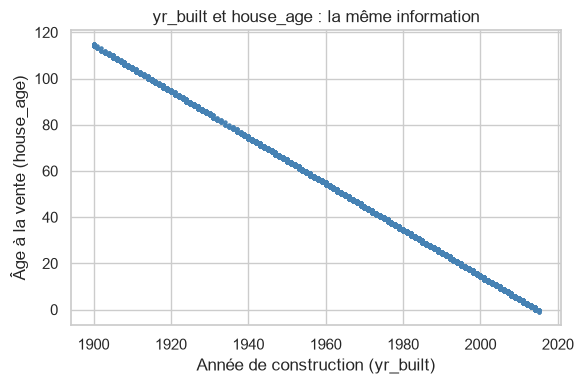

Colonnes restantes (21) : ['price', 'bedrooms', 'bathrooms', 'sqft_living', 'sqft_lot', 'floors', 'waterfront', 'view', 'condition', 'grade', 'sqft_basement', 'zipcode', 'lat', 'long', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'house_age', 'renovated', 'has_basement']


In [8]:
# Relation exacte : house_age + yr_built = sale_year sur toutes les lignes
assert (df["house_age"] + df["yr_built"] == df["sale_year"]).all(), "La relation house_age = sale_year - yr_built n'est pas vérifiée"
print("house_age + yr_built == sale_year sur toutes les lignes")
print(f"Corrélation entre yr_built et house_age : {df['yr_built'].corr(df['house_age']):.4f}")

fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(df["yr_built"], df["house_age"], s=4, alpha=0.3, color="steelblue")
ax.set_xlabel("Année de construction (yr_built)")
ax.set_ylabel("Âge à la vente (house_age)")
ax.set_title("yr_built et house_age : la même information")
plt.tight_layout()
plt.show()

df = df.drop(columns="yr_built")
print(f"Colonnes restantes ({df.shape[1]}) : {list(df.columns)}")

### 1.8 Distribution de la cible : `price` ou `log1p(price)` ?

**Quoi :** on compare la distribution du prix brut et celle de `log1p(price)` = log(1 + prix), avec leur coefficient d'asymétrie (*skewness*). Une distribution symétrique a une skewness proche de 0.

**Pourquoi :** les prix immobiliers ont en général une distribution très **asymétrique à droite** : beaucoup de maisons à prix moyen, quelques maisons de luxe très chères. On vérifie si c'est le cas ici, car cela conditionne le choix de la cible.

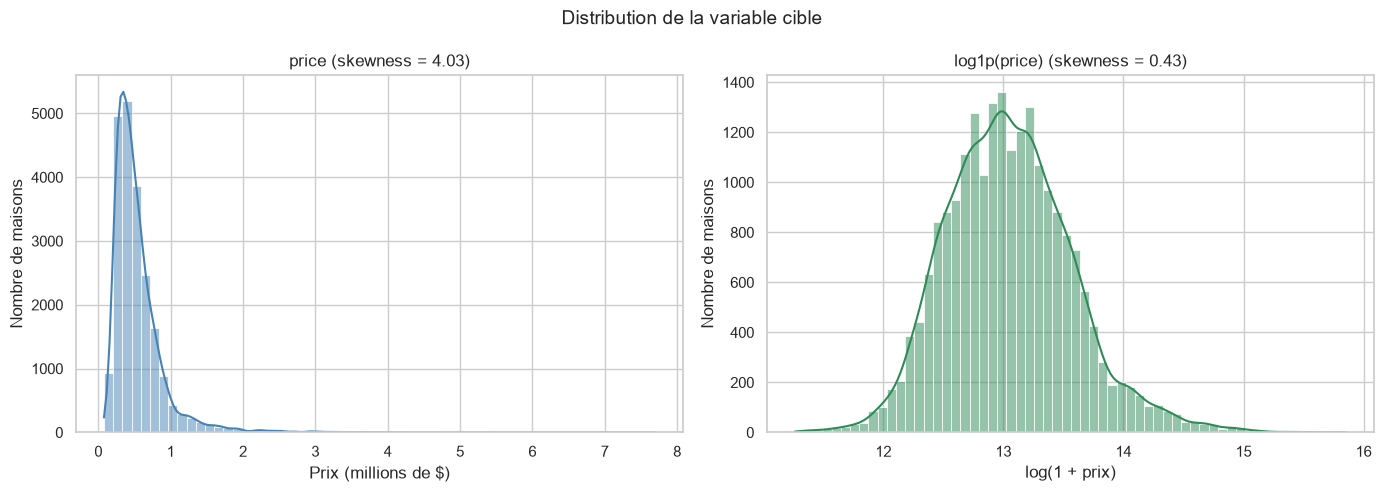

Skewness de price        : 4.03
Skewness de log1p(price) : 0.43


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.histplot(df["price"] / 1e6, bins=60, kde=True, ax=axes[0], color="steelblue")
axes[0].set_title(f"price (skewness = {df['price'].skew():.2f})")
axes[0].set_xlabel("Prix (millions de $)")
axes[0].set_ylabel("Nombre de maisons")

sns.histplot(np.log1p(df["price"]), bins=60, kde=True, ax=axes[1], color="seagreen")
axes[1].set_title(f"log1p(price) (skewness = {np.log1p(df['price']).skew():.2f})")
axes[1].set_xlabel("log(1 + prix)")
axes[1].set_ylabel("Nombre de maisons")

plt.suptitle("Distribution de la variable cible", fontsize=14)
plt.tight_layout()
plt.show()

print(f"Skewness de price        : {df['price'].skew():.2f}")
print(f"Skewness de log1p(price) : {np.log1p(df['price']).skew():.2f}")

**Décision : la cible des modèles sera `log1p(price)`.**

- **Distribution :** le prix brut est fortement asymétrique (skewness ≈ 4,0, avec une longue traîne jusqu'à près de 8 M$). Après `log1p`, la distribution est presque en cloche : la skewness tombe à ≈ 0,4, une asymétrie faible (on parle en général de forte asymétrie au-delà de 1). Les régressions linéaires et Ridge supposent des erreurs à peu près symétriques et de variance constante, et le log s'en rapproche nettement.
- **Poids des maisons de luxe :** avec le prix brut, une erreur de 100 000 $ sur une maison à 5 M$ pèse autant que sur une maison à 300 000 $, et les quelques maisons très chères dominent l'apprentissage. En log, le modèle minimise des **erreurs relatives** (en %), ce qui correspond mieux au besoin : se tromper de 10 % est aussi grave pour une petite maison que pour une grande.
- **Pas de fuite :** `log1p` est une fonction fixe qui n'apprend rien des données, donc on peut l'appliquer sans risque. Pour revenir au prix en dollars, on appliquera `np.expm1()` aux prédictions. Les métriques finales (MAE, RMSE) seront calculées **en dollars**, pour rester interprétables.

On garde `price` en dollars dans le fichier nettoyé. La transformation sera appliquée au moment de la modélisation.

### 1.9 `zipcode` : une variable catégorielle

**Quoi :** on regarde `zipcode` sans le transformer.

**Pourquoi :** `zipcode` est stocké comme un nombre, mais c'est un **code postal**, c'est-à-dire une étiquette de zone géographique. Les calculs sur ces nombres n'ont aucun sens : 98 178 n'est pas « plus grand » ou « deux fois » 98 039, et deux codes proches ne désignent pas forcément des quartiers semblables. Un modèle linéaire qui le lirait comme un nombre en tirerait une relation absurde.

Il faudra donc l'**encoder** (par exemple en one-hot, ou en *target encoding* avec le prix moyen par zone). Cet encodage dépend des données : la liste des catégories, et surtout le prix moyen par zone pour le target encoding, qui utilise la cible. **Il se fera donc après le split, ajusté sur le train uniquement.** Ici, on se contente de constater sa nature.

In [10]:
print(f"Nombre de codes postaux distincts : {df['zipcode'].nunique()}")

prix_median_zip = df.groupby("zipcode")["price"].median().sort_values()
print(f"\nPrix médian par zipcode : de {prix_median_zip.iloc[0]:,.0f} $ ({prix_median_zip.index[0]}) "
      f"à {prix_median_zip.iloc[-1]:,.0f} $ ({prix_median_zip.index[-1]})")
print("Exemple de trois codes consécutifs aux prix très différents :")
print(prix_median_zip.loc[[98038, 98039, 98040]].apply(lambda p: f"{p:,.0f} $").to_string())

Nombre de codes postaux distincts : 70

Prix médian par zipcode : de 235,000 $ (98002) à 1,892,500 $ (98039)
Exemple de trois codes consécutifs aux prix très différents :
zipcode
98038      342,000 $
98039    1,892,500 $
98040      993,750 $


### 1.10 Vérification finale et sauvegarde

**Quoi :** on affiche les dimensions finales, on vérifie qu'il ne reste aucune valeur manquante, puis on sauvegarde le dataset dans `data/processed/kc_house_clean.csv`.

**Pourquoi :** sauvegarder le dataset nettoyé fige une version de référence. On peut la recharger sans refaire le nettoyage, et l'application ou d'autres notebooks peuvent s'en servir. Ce fichier ne contient **que** des transformations sans apprentissage : il reste sûr à utiliser avant le split.

In [11]:
print(f"Dimensions finales : {df.shape[0]} lignes x {df.shape[1]} colonnes")
print(f"Valeurs manquantes : {df.isna().sum().sum()}")
assert df.isna().sum().sum() == 0, "Il reste des valeurs manquantes"

CHEMIN_PROPRE = "../data/processed/kc_house_clean.csv"
df.to_csv(CHEMIN_PROPRE, index=False)
print(f"Dataset nettoyé sauvegardé dans {CHEMIN_PROPRE}")

display(df.head())

Dimensions finales : 21597 lignes x 21 colonnes
Valeurs manquantes : 0
Dataset nettoyé sauvegardé dans ../data/processed/kc_house_clean.csv


,price,bedrooms,bathrooms,sqft_living,sqft_lot,floors,waterfront,view,condition,grade,sqft_basement,zipcode,lat,long,sqft_living15,sqft_lot15,sale_year,sale_month,house_age,renovated,has_basement
0,221900.0,3,1.00,1180,5650,1.0,0,0,3,7,0,98178,47.5112,-122.257,1340,5650,2014,10,59,0,0
1,538000.0,3,2.25,2570,7242,2.0,0,0,3,7,400,98125,47.7210,-122.319,1690,7639,2014,12,63,1,1
2,180000.0,2,1.00,770,10000,1.0,0,0,3,6,0,98028,47.7379,-122.233,2720,8062,2015,2,82,0,0
3,604000.0,4,3.00,1960,5000,1.0,0,0,5,7,910,98136,47.5208,-122.393,1360,5000,2014,12,49,0,1
4,510000.0,3,2.00,1680,8080,1.0,0,0,3,8,0,98074,47.6168,-122.045,1800,7503,2015,2,28,0,0


## 2. Séparation train / test

**Quoi :** on définit les variables explicatives `X` (toutes les colonnes sauf `price`) et la cible `y = log1p(price)` (voir 1.8), puis on les sépare en un jeu d'entraînement (80 %) et un jeu de test (20 %), avec `random_state=RANDOM_STATE`.

**Pourquoi :**
- Le jeu de test joue le rôle de **maisons jamais vues**. Il ne servira **qu'une seule fois**, à l'évaluation finale (section 6). Aucune décision ne doit s'appuyer dessus : ni l'encodage, ni la sélection de features, ni le choix du modèle, ni les hyperparamètres. Sinon, la performance annoncée serait trop optimiste. Toutes les comparaisons intermédiaires se feront par **validation croisée sur le train**.
- **80 / 20** est un compromis classique : environ 17 000 ventes pour apprendre, et environ 4 300 pour une mesure finale stable.
- Le découpage est aléatoire (sans stratification, la cible étant continue). On vérifie ensuite que la distribution des prix est comparable dans les deux jeux.

In [12]:
# Variables explicatives : toutes les colonnes sauf la cible
X = df.drop(columns="price")
# Cible : log(1 + prix), plus symétrique que le prix brut
y = np.log1p(df["price"])

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE
)

print(f"Train : {X_train.shape[0]} lignes x {X_train.shape[1]} features ({len(X_train) / len(X):.0%})")
print(f"Test  : {X_test.shape[0]} lignes x {X_test.shape[1]} features ({len(X_test) / len(X):.0%})")

# Vérification : les deux jeux ont des distributions de prix comparables (en dollars)
comparaison = pd.DataFrame({
    "train ($)": np.expm1(y_train).describe(),
    "test ($)": np.expm1(y_test).describe(),
}).loc[["mean", "25%", "50%", "75%", "max"]]
comparaison.index = ["moyenne", "1er quartile", "médiane", "3e quartile", "maximum"]
display(comparaison.round(0))

Train : 17277 lignes x 20 features (80%)
Test  : 4320 lignes x 20 features (20%)


,train ($),test ($)
moyenne,541420.0,535336.0
1er quartile,324000.0,319800.0
médiane,450000.0,450000.0
3e quartile,645500.0,637500.0
maximum,7700000.0,7062500.0


**Constat :** les deux jeux ont des prix moyens, médians et des quartiles très proches. Le découpage aléatoire n'a pas créé de déséquilibre. À partir d'ici, `X_test` et `y_test` sont **mis de côté** jusqu'à la section 6.

> **Rappel de la limite des reventes (voir 1.2) :** 176 maisons ont été vendues plusieurs fois (353 lignes, soit 1,6 % du dataset). Le découpage étant aléatoire, une vente peut se retrouver dans le train et une autre vente de la même maison dans le test. Le modèle a alors déjà « vu » cette maison, ce qui rend la prédiction un peu plus facile. Vu la faible proportion, l'effet sur les métriques est négligeable. Une alternative plus stricte serait un découpage groupé par `id` (`GroupShuffleSplit`).

## 3. Sélection de features

**Objectif :** identifier les variables réellement utiles pour prédire le prix, avec deux méthodes complémentaires :
- **Boruta** (3.3) répond à la question « cette variable apporte-t-elle de l'information ? » (approche *all-relevant*) ;
- la **forward selection** (3.4) répond à « quel est le plus petit groupe de variables qui suffit ? » (approche *minimal-optimal*), en écartant les variables redondantes.

**Règle :** toute cette section travaille **uniquement sur le train**. L'encodage de `zipcode` et les deux méthodes de sélection apprennent des données : les faire sur tout le dataset ferait fuiter de l'information du jeu de test.

La liste finale de features sera arrêtée **après** ces analyses, en croisant la performance et l'utilisabilité dans l'application (un utilisateur doit pouvoir saisir chaque variable).

### 3.1 Encodage de `zipcode` par *target encoding*

**Quoi :** on remplace chaque code postal par le **log-prix moyen de sa zone**, calculé sur le train avec `TargetEncoder(cv=KFold(5, shuffle=True, random_state=RANDOM_STATE))`.

**Pourquoi le target encoding plutôt que le one-hot :**
- **Le one-hot crée 70 colonnes** binaires (une par code postal), dont beaucoup ne concernent que quelques dizaines de ventes. Boruta et la forward selection devraient évaluer chaque code postal séparément, ce qui est lent (la forward selection teste chaque colonne restante à chaque étape) et peu parlant : on veut savoir si **la localisation** compte, pas si le code 98 039 compte.
- **Le target encoding garde une seule colonne numérique**, ordonnée par niveau de prix de la zone. C'est exactement l'information utile (« quartier cher ou bon marché »). Les modèles à arbres l'exploitent en une seule coupure, et les modèles linéaires peuvent l'utiliser directement.
- Dans le formulaire Flask, l'utilisateur saisira simplement un code postal, que l'encodeur convertira.

**Le risque, et comment `TargetEncoder` le gère :** l'encodage utilise la cible, donc une ligne pourrait « voir » son propre prix dans sa feature (fuite). `fit_transform` applique un **cross-fitting** : le train est découpé en 5 blocs (mélangés, avec `random_state=RANDOM_STATE` pour la reproductibilité), et l'encodage de chaque ligne est calculé uniquement à partir des 4 autres blocs. De plus, les zones peu représentées sont **lissées** vers la moyenne globale (`smooth="auto"`), ce qui évite de leur attribuer une moyenne bruitée.

> On passe le découpage via `cv=KFold(...)` plutôt que `random_state=` directement : depuis scikit-learn 1.9, les paramètres `shuffle` et `random_state` de `TargetEncoder` sont dépréciés (suppression prévue en 1.11).

> `fit_transform` (avec cross-fitting) n'est pas équivalent à `fit` puis `transform`. Pour le test et l'application, on utilisera `transform`, qui applique l'encodage appris sur tout le train. Pour l'entraînement des modèles (section 4), l'encodeur sera placé dans un `Pipeline`, afin d'être réajusté à chaque pli de validation croisée.

In [13]:
encodeur_zip = TargetEncoder(
    target_type="continuous",
    cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
)

# Copie du train, avec zipcode remplacé par son encodage (cross-fitting via fit_transform)
X_train_enc = X_train.copy()
X_train_enc["zipcode"] = encodeur_zip.fit_transform(X_train[["zipcode"]], y_train).ravel()

# Encodage appris par zone sur tout le train, reconverti en dollars pour être lisible
encodage_par_zip = pd.Series(encodeur_zip.encodings_[0], index=encodeur_zip.categories_[0])
print(f"Codes postaux appris sur le train : {len(encodage_par_zip)}")
print(f"Moyenne globale du train : {np.expm1(encodeur_zip.target_mean_):,.0f} $ (prix typique)")

extremes = encodage_par_zip.sort_values().iloc[[0, 1, 2, -3, -2, -1]]
print("\nZones les moins chères et les plus chères (prix typique encodé) :")
print(np.expm1(extremes).apply(lambda p: f"{p:,.0f} $").to_string())

display(X_train_enc[["zipcode"]].rename(columns={"zipcode": "zipcode encodé"})
        .assign(zipcode_original=X_train["zipcode"]).head())

Codes postaux appris sur le train : 70
Moyenne globale du train : 464,948 $ (prix typique)

Zones les moins chères et les plus chères (prix typique encodé) :
98002      230,243 $
98168      230,768 $
98032      243,039 $
98040    1,103,329 $
98004    1,172,823 $
98039    1,983,907 $


,zipcode encodé,zipcode_original
6243,13.158789,98144
8986,12.905111,98045
9419,13.362611,98074
10155,13.098951,98034
10436,13.212643,98103


### 3.2 Corrélations entre features et avec la cible

**Quoi :** on calcule la matrice de corrélation de Pearson sur le train (avec `zipcode` encodé et la cible `log_price`), puis on liste les features les plus corrélées à la cible et les paires de features très corrélées entre elles (|r| > 0,8).

**Pourquoi :** c'est une première lecture rapide. Une forte corrélation avec la cible signale une variable prometteuse. Une forte corrélation entre deux features signale une **redondance** : elle gêne les modèles linéaires (coefficients instables), et l'une des deux pourra probablement être retirée sans perte. Limite : Pearson ne mesure que les relations **linéaires**. Une variable comme `lat` ou `long`, dont l'effet sur le prix n'est pas monotone, peut être sous-estimée. C'est pourquoi on complète cette lecture par Boruta et la forward selection.

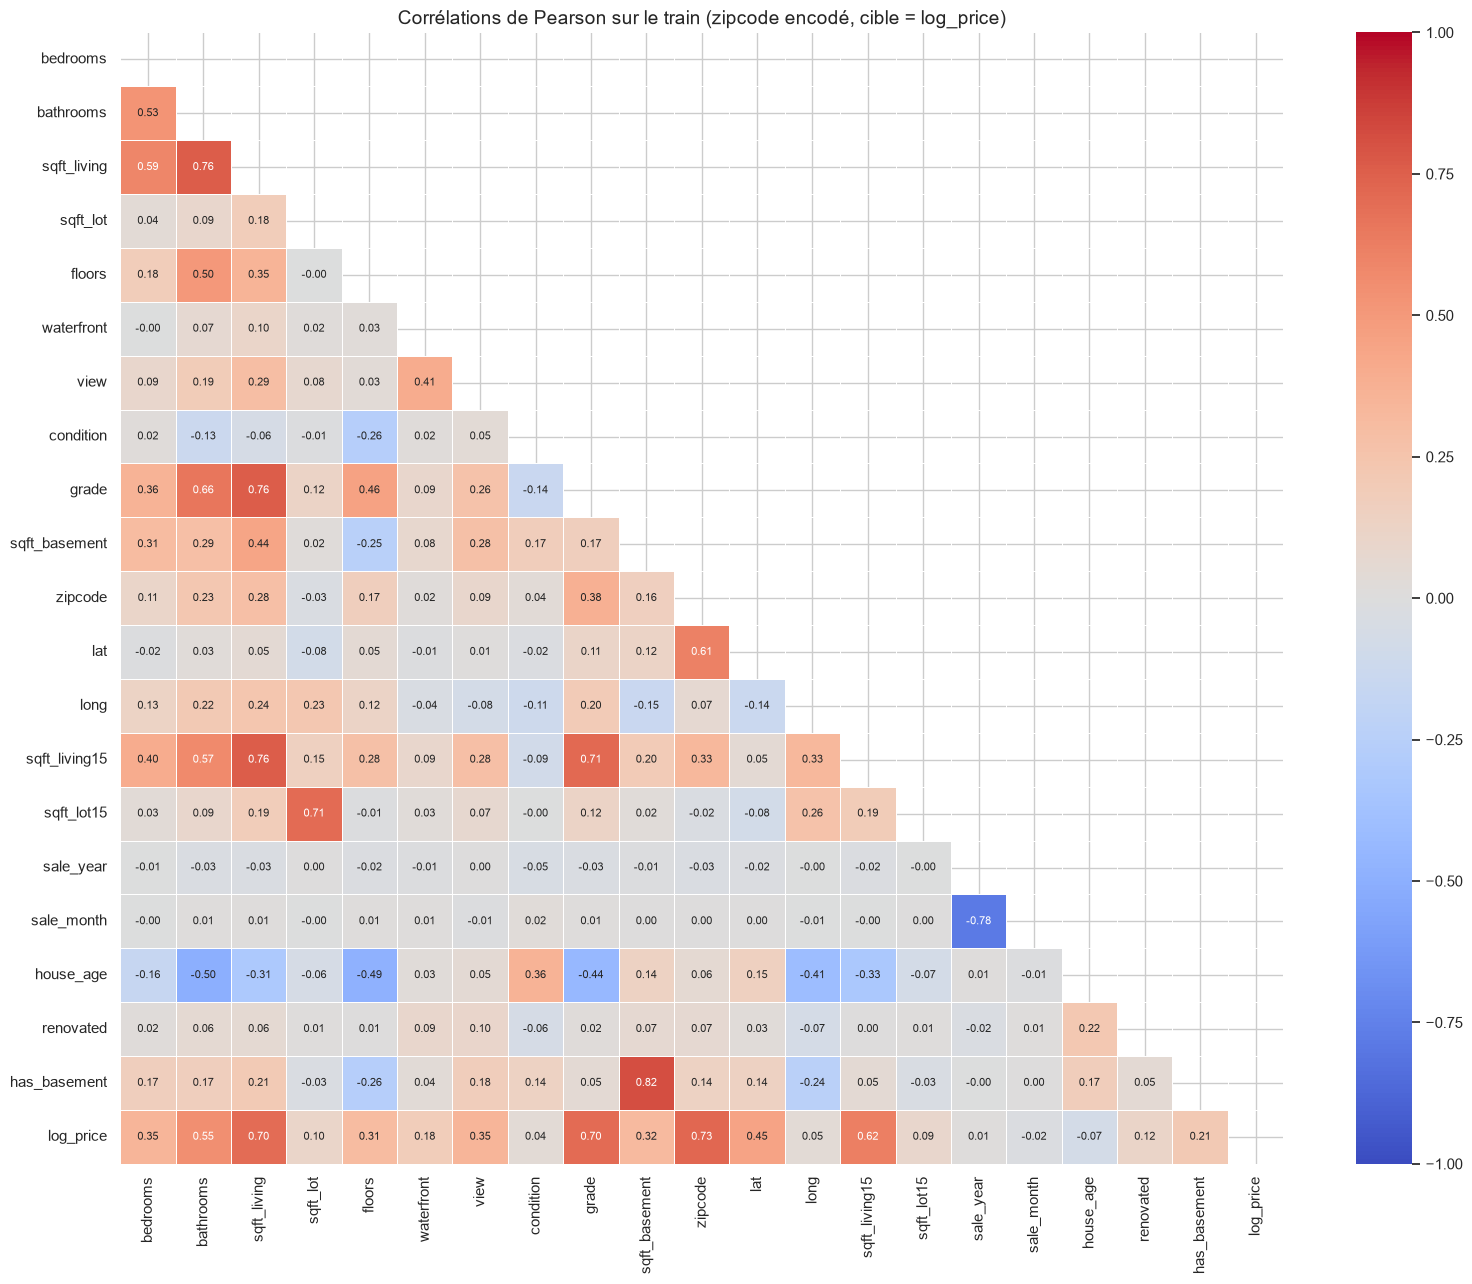

Corrélation avec log(price) :
zipcode          0.725
grade            0.704
sqft_living      0.695
sqft_living15    0.623
bathrooms        0.553
lat              0.449
view             0.351
bedrooms         0.348
sqft_basement    0.319
floors           0.312
has_basement     0.214
waterfront       0.181
renovated        0.116
sqft_lot         0.103
sqft_lot15       0.091
house_age       -0.072
long             0.046
condition        0.042
sale_month      -0.018
sale_year        0.009

Paires de features avec |r| > 0,8 : 1
sqft_basement  has_basement    0.82


In [14]:
donnees_corr = X_train_enc.assign(log_price=y_train)
matrice_corr = donnees_corr.corr()

# Heatmap du triangle inférieur (la matrice est symétrique)
masque_triangle = np.triu(np.ones_like(matrice_corr, dtype=bool))
fig, ax = plt.subplots(figsize=(16, 13))
sns.heatmap(matrice_corr, mask=masque_triangle, annot=True, fmt=".2f", cmap="coolwarm",
            center=0, vmin=-1, vmax=1, annot_kws={"size": 8}, linewidths=0.5, ax=ax)
ax.set_title("Corrélations de Pearson sur le train (zipcode encodé, cible = log_price)", fontsize=14)
plt.tight_layout()
plt.show()

# Corrélation de chaque feature avec la cible, triée par valeur absolue
corr_cible = matrice_corr["log_price"].drop("log_price").sort_values(key=abs, ascending=False)
print("Corrélation avec log(price) :")
print(corr_cible.round(3).to_string())

# Paires de features fortement corrélées entre elles (triangle supérieur strict, sans doublon)
corr_features = matrice_corr.drop(index="log_price", columns="log_price")
triangle_sup = np.triu(np.ones(corr_features.shape, dtype=bool), k=1)
paires = corr_features.where(triangle_sup).stack()
paires_fortes = paires[paires.abs() > 0.8].sort_values(key=abs, ascending=False)
print(f"\nPaires de features avec |r| > 0,8 : {len(paires_fortes)}")
print(paires_fortes.round(3).to_string())

**Lecture des corrélations :**
- **Les plus liées à `log(price)` :** `zipcode` encodé (0,73), `grade` (0,70), `sqft_living` (0,70), `sqft_living15` (0,62) et `bathrooms` (0,55). Le prix dépend donc avant tout de la **localisation**, de la **qualité de construction** et de la **surface**. `lat` (0,45) confirme l'effet géographique : le nord du comté (Seattle, Bellevue) est plus cher que le sud.
- **Quasi nulles linéairement :** `sale_year`, `sale_month`, `condition`, `long` et `house_age` (|r| < 0,08). Cela ne veut pas dire qu'elles sont inutiles : leur effet peut être non linéaire. Par exemple, les maisons très anciennes et les maisons neuves sont toutes deux recherchées, et `long` agit à travers des zones précises. Boruta et la forward selection trancheront.
- **Paire au-dessus de 0,8 :** une seule, `sqft_basement` / `has_basement` (0,82), ce qui est logique puisque `has_basement` est dérivée de `sqft_basement`. L'une des deux est redondante.
- **Juste en dessous du seuil :** `sale_year` / `sale_month` (-0,78, car les ventes de 2015 s'arrêtent en mai), `sqft_living` / `grade` (0,76), `sqft_living` / `sqft_living15` (0,76) et `sqft_living` / `bathrooms` (0,76). Ce sont des redondances partielles, dont la forward selection devrait écarter une partie.

### 3.3 Boruta

**Quoi :** Boruta crée pour chaque feature une copie dont les valeurs sont mélangées aléatoirement (*shadow feature*), donc sans aucun lien avec le prix. Il entraîne une forêt aléatoire sur l'ensemble, puis compare l'importance de chaque vraie feature à celle de la **meilleure shadow feature**. L'opération est répétée, et un test statistique classe chaque feature :
- **confirmée** : elle bat le hasard significativement plus souvent qu'attendu ;
- **rejetée** : elle ne fait pas mieux que du bruit ;
- **tentative** : pas assez d'itérations pour trancher.

Le `ranking` vaut 1 pour les features confirmées, 2 pour les tentatives, et augmente pour les features rejetées tôt.

**Pourquoi Boruta :** il repose sur une forêt aléatoire, donc il capte les relations **non linéaires** et les interactions, que la corrélation ignore (par exemple `lat`). Le seuil « faire mieux que du bruit » est objectif, plutôt qu'un seuil d'importance choisi arbitrairement.

**Paramètres :**
- `max_depth=7` : des arbres peu profonds, comme le recommandent les auteurs de Boruta (profondeur de 3 à 7), pour que les importances restent comparables et que le calcul soit rapide.
- `n_estimators="auto"` : le nombre d'arbres est ajusté au nombre de features à chaque itération.
- `max_iter=50` : limite la durée. Quelques features peuvent rester « tentatives ».
- `n_jobs=-1` : tous les cœurs du processeur sont utilisés.

In [15]:
foret_boruta = RandomForestRegressor(n_jobs=-1, max_depth=7, random_state=RANDOM_STATE)
boruta = BorutaPy(foret_boruta, n_estimators="auto", max_iter=50, random_state=RANDOM_STATE)

debut = time.perf_counter()
# BorutaPy attend des tableaux NumPy, pas des DataFrame
boruta.fit(X_train_enc.to_numpy(), y_train.to_numpy())
print(f"Durée de Boruta : {time.perf_counter() - debut:.0f} s")

statut_boruta = np.select([boruta.support_, boruta.support_weak_], ["confirmée", "tentative"], default="rejetée")
resultats_boruta = (
    pd.DataFrame({"feature": X_train_enc.columns, "statut": statut_boruta, "ranking": boruta.ranking_})
    .sort_values(["ranking", "feature"])
    .reset_index(drop=True)
)
display(resultats_boruta)
print(resultats_boruta["statut"].value_counts().to_string())

Durée de Boruta : 44 s


,feature,statut,ranking
0,bathrooms,confirmée,1
1,condition,confirmée,1
2,grade,confirmée,1
3,house_age,confirmée,1
4,lat,confirmée,1
5,long,confirmée,1
6,sqft_living,confirmée,1
7,sqft_living15,confirmée,1
8,sqft_lot,confirmée,1
9,sqft_lot15,confirmée,1


statut
confirmée    13
rejetée       7


**Résultat de Boruta :** **13 features confirmées et 7 rejetées**, aucune tentative : 50 itérations ont suffi à trancher.
- **Confirmées :** la localisation (`zipcode`, `lat`, `long`), la surface (`sqft_living`, `sqft_lot`), la qualité (`grade`, `condition`, `view`, `waterfront`), l'âge (`house_age`), `bathrooms`, ainsi que les variables de voisinage `sqft_living15` et `sqft_lot15`. Comme attendu, `condition`, `long` et `house_age`, presque décorrélées linéairement de la cible, sont bien utiles de façon non linéaire.
- **Rejetées :** `bedrooms` et `floors` (leur information est déjà portée par `sqft_living`), `sqft_basement` et `has_basement`, `renovated` (seulement 4 % des maisons), ainsi que `sale_year` et `sale_month` (la période couverte, 13 mois, est trop courte pour qu'un effet de marché pèse face aux caractéristiques de la maison).

### 3.4 Forward selection

**Quoi :** la forward selection part d'un ensemble **vide**. À chaque étape, elle ajoute la feature qui améliore le plus le R² en validation croisée à 3 plis. Elle s'arrête quand plus aucun ajout n'améliore le R² d'au moins `tol=0.001` (`n_features_to_select="auto"`).

**Pourquoi :** contrairement à Boruta, elle évalue les features **ensemble**. Une variable informative mais redondante (par exemple `sqft_living15`, si `sqft_living` est déjà retenue) n'apporte presque rien une fois sa « jumelle » choisie, et elle n'est donc pas ajoutée. On obtient un ensemble **minimal** et performant.

**Pourquoi `HistGradientBoostingRegressor` comme estimateur :**
- **rapide** : il regroupe les valeurs en histogrammes (255 intervalles) et utilise tous les cœurs. C'est important ici, car la forward selection entraîne des centaines de modèles (une vingtaine de candidats × 3 plis × plusieurs étapes) ;
- **non linéaire** : comme la forêt de Boruta et les modèles de la section 4, il capte les effets non monotones (`lat`, `long`) et les interactions. Une régression linéaire sous-estimerait ces variables.

> Les plis (`cv=3`) ne sont pas mélangés, mais le train l'est déjà par `train_test_split`. Limite mineure : `zipcode` a été encodé une seule fois avant cette validation croisée, ce qui peut avantager légèrement cette feature. Cela n'a pas d'incidence sur la sélection d'une variable de localisation aussi forte.

In [16]:
estimateur_forward = HistGradientBoostingRegressor(random_state=RANDOM_STATE)
selecteur_forward = SequentialFeatureSelector(
    estimateur_forward,
    direction="forward",
    n_features_to_select="auto",
    tol=0.001,
    scoring="r2",
    cv=3,
    n_jobs=-1,
)

debut = time.perf_counter()
selecteur_forward.fit(X_train_enc, y_train)
print(f"Durée de la forward selection : {time.perf_counter() - debut:.0f} s")

features_forward = list(selecteur_forward.get_feature_names_out())
features_ecartees = [f for f in X_train_enc.columns if f not in features_forward]
print(f"\nFeatures retenues ({len(features_forward)}) : {features_forward}")
print(f"Features écartées ({len(features_ecartees)}) : {features_ecartees}")

# Ce que coûte la réduction : R² en validation croisée avec toutes les features vs la sélection
plis = KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
r2_toutes = cross_val_score(estimateur_forward, X_train_enc, y_train, cv=plis, scoring="r2").mean()
r2_forward = cross_val_score(estimateur_forward, X_train_enc[features_forward], y_train, cv=plis, scoring="r2").mean()
print(f"\nR² (log-prix, CV 3 plis) avec les {X_train_enc.shape[1]} features : {r2_toutes:.4f}")
print(f"R² (log-prix, CV 3 plis) avec les {len(features_forward)} features retenues : {r2_forward:.4f}")

Durée de la forward selection : 106 s

Features retenues (13) : ['sqft_living', 'sqft_lot', 'waterfront', 'view', 'condition', 'grade', 'sqft_basement', 'zipcode', 'lat', 'long', 'sale_year', 'house_age', 'renovated']
Features écartées (7) : ['bedrooms', 'bathrooms', 'floors', 'sqft_living15', 'sqft_lot15', 'sale_month', 'has_basement']

R² (log-prix, CV 3 plis) avec les 20 features : 0.8992
R² (log-prix, CV 3 plis) avec les 13 features retenues : 0.8987


**Résultat de la forward selection :** **13 features retenues**, et la réduction ne coûte rien : le R² passe de 0,8992 (20 features) à 0,8987 (13 features).
- Elle **écarte des features que Boruta juge informatives, mais redondantes** : `sqft_living15` (redondante avec `sqft_living` et `zipcode`), `sqft_lot15` (avec `sqft_lot`) et `bathrooms` (avec `sqft_living` et `grade`).
- À l'inverse, elle **retient trois features rejetées par Boruta** : `sqft_basement`, `renovated` et `sale_year`. Chacune apporte un petit gain marginal (au moins 0,001 de R²) une fois les variables principales en place. Leur intérêt réel est donc faible.

### 3.5 Tableau comparatif

**Quoi :** on rassemble, pour chaque feature, le verdict de Boruta, celui de la forward selection et sa corrélation avec `log(price)`, triés par corrélation absolue décroissante.

**Pourquoi :** aucune méthode ne suffit seule. Une feature retenue par les deux méthodes est un choix sûr. Une feature retenue par Boruta seulement est informative, mais probablement redondante. Une feature rejetée par les deux peut être retirée sans regret. Ce tableau sert de base à la décision sur la liste finale.

In [17]:
comparatif = pd.DataFrame(index=pd.Index(X_train_enc.columns, name="feature"))
comparatif["Boruta"] = (resultats_boruta.set_index("feature")["statut"]
                        .map({"confirmée": "oui", "tentative": "tentative", "rejetée": "non"}))
comparatif["forward"] = np.where(comparatif.index.isin(features_forward), "oui", "non")
comparatif["corrélation avec log(price)"] = corr_cible.round(3)
comparatif = comparatif.loc[comparatif["corrélation avec log(price)"].abs().sort_values(ascending=False).index]

display(comparatif)
deux_methodes = comparatif.index[(comparatif["Boruta"] == "oui") & (comparatif["forward"] == "oui")].tolist()
print(f"Retenues par les deux méthodes ({len(deux_methodes)}) : {deux_methodes}")

,Boruta,forward,corrélation avec log(price)
feature,,,
zipcode,oui,oui,0.725
grade,oui,oui,0.704
sqft_living,oui,oui,0.695
sqft_living15,oui,non,0.623
bathrooms,oui,non,0.553
lat,oui,oui,0.449
view,oui,oui,0.351
bedrooms,non,non,0.348
sqft_basement,non,oui,0.319


Retenues par les deux méthodes (10) : ['zipcode', 'grade', 'sqft_living', 'lat', 'view', 'waterfront', 'sqft_lot', 'house_age', 'long', 'condition']


**Bilan :** les deux méthodes s'accordent sur **10 features** : `zipcode`, `grade`, `sqft_living`, `lat`, `view`, `waterfront`, `sqft_lot`, `house_age`, `long` et `condition`. Elles forment le cœur du modèle.
- **Écartées par les deux méthodes :** `bedrooms`, `floors`, `has_basement` et `sale_month`. On peut les retirer sans regret.
- **Désaccords :** `sqft_living15`, `sqft_lot15` et `bathrooms` sont informatives mais redondantes (Boruta oui, forward non). `sqft_basement`, `renovated` et `sale_year` apportent un faible gain marginal (Boruta non, forward oui).

La liste finale sera arrêtée en croisant ces résultats avec l'**utilisabilité dans l'application** : chaque feature retenue doit pouvoir être saisie facilement par un utilisateur.

### 3.6 Choix final des features

**Quoi :** on fixe la liste des features du modèle final, en croisant deux critères :
1. **la performance** : verdicts de Boruta et de la forward selection (3.5), puis vérification par validation croisée (ci-dessous) ;
2. **l'utilisabilité dans l'application Flask** : un utilisateur doit pouvoir renseigner chaque feature facilement dans un formulaire.

**Pourquoi ce second critère :** un modèle n'est utile que si on peut l'alimenter. Une feature excellente mais impossible à saisir (par exemple la surface moyenne des 15 maisons voisines) obligerait l'utilisateur à inventer une valeur, et la prédiction serait faussée.

**Liste retenue : 12 features**

| Feature | Performance | Saisie dans le formulaire |
|---|---|---|
| `sqft_living` | Boruta + forward ; 3e corrélation (0,70) | Surface habitable : un nombre |
| `grade` | Boruta + forward ; 2e corrélation (0,70) | Qualité de construction (1 à 13) : liste déroulante avec libellés |
| `zipcode` | Boruta + forward ; 1re corrélation une fois encodé (0,73) | Code postal : liste des 70 codes connus |
| `lat`, `long` | Boruta + forward ; effet non linéaire fort (voir la validation ci-dessous) | **Clic sur une carte Leaflet**, centrée par défaut sur la médiane du zipcode (calculée sur le train, voir 3.7), qui sert aussi de valeur de repli |
| `view` | Boruta + forward | Qualité de la vue (0 à 4) : liste déroulante |
| `waterfront` | Boruta + forward | Bord de l'eau : case à cocher |
| `sqft_lot` | Boruta + forward | Surface du terrain : un nombre |
| `condition` | Boruta + forward | État général (1 à 5) : liste déroulante |
| `house_age` | Boruta + forward | L'utilisateur saisit l'**année de construction**, et l'âge est calculé avec 2015 comme année de référence (celle des prix du dataset) |
| `sqft_basement` | Forward seulement (petit gain marginal) | Surface du sous-sol : un nombre, 0 s'il n'y en a pas |
| `renovated` | Forward seulement (petit gain marginal) | Déjà rénovée : case à cocher |

**Features exclues : 8**

| Feature | Raison |
|---|---|
| `sqft_living15`, `sqft_lot15` | Impossibles à saisir (moyennes des 15 voisins), et la forward selection les écarte comme redondantes avec `sqft_living`, `sqft_lot` et `zipcode` : aucune perte |
| `bathrooms` | Retenue par Boruta, mais redondante avec `sqft_living` et `grade` : la forward selection ne l'ajoute pas |
| `bedrooms`, `floors` | Rejetées par les deux méthodes : leur information est déjà portée par `sqft_living` |
| `has_basement` | Rejetée par les deux méthodes ; redondante avec `sqft_basement` (r = 0,82) |
| `sale_month` | Rejetée par les deux méthodes |
| `sale_year` | Petit gain dans la forward selection, mais sans sens dans un formulaire (ce serait toujours la même valeur). On précisera dans l'application que les estimations correspondent aux **prix de 2014-2015** |

In [18]:
FEATURES_FINALES = [
    "sqft_living",    # surface habitable
    "grade",          # qualité de construction (1 à 13)
    "zipcode",        # code postal (target encoding)
    "lat",            # latitude (carte, repli : médiane du zipcode)
    "long",           # longitude (carte, repli : médiane du zipcode)
    "view",           # qualité de la vue (0 à 4)
    "waterfront",     # bord de l'eau (0 / 1)
    "sqft_lot",       # surface du terrain
    "condition",      # état général (1 à 5)
    "house_age",      # âge, calculé à partir de l'année de construction
    "sqft_basement",  # surface du sous-sol (0 si aucun)
    "renovated",      # déjà rénovée (0 / 1)
]
features_exclues = [f for f in X_train.columns if f not in FEATURES_FINALES]

assert len(FEATURES_FINALES) == 12 and set(FEATURES_FINALES) <= set(X_train.columns)
print(f"Features finales ({len(FEATURES_FINALES)}) : {FEATURES_FINALES}")
print(f"Features exclues ({len(features_exclues)}) : {features_exclues}")

Features finales (12) : ['sqft_living', 'grade', 'zipcode', 'lat', 'long', 'view', 'waterfront', 'sqft_lot', 'condition', 'house_age', 'sqft_basement', 'renovated']
Features exclues (8) : ['bedrooms', 'bathrooms', 'floors', 'sqft_living15', 'sqft_lot15', 'sale_year', 'sale_month', 'has_basement']


#### Validation : ce que coûte chaque choix

**Quoi :** on compare cinq jeux de features par **validation croisée à 5 plis sur le train**, avec le même estimateur que la forward selection (`HistGradientBoostingRegressor`) :
- toutes les features (20), comme référence haute ;
- la sélection de la forward selection (13) ;
- la liste finale (12), avec les vraies `lat`/`long` : c'est le cas où l'utilisateur clique sur la carte ;
- la liste finale, avec `lat`/`long` remplacées par la médiane du zipcode : c'est le cas de repli ;
- la liste finale sans `lat`/`long`, pour mesurer ce qu'apporte la carte.

On rapporte le R² sur `log(price)` et la **MAE en dollars** (après `np.expm1`), plus parlante.

**Pourquoi refaire l'encodage dans chaque pli :** dans chaque pli, le `TargetEncoder` et les médianes de `lat`/`long` sont **ajustés sur la partie apprentissage du pli uniquement**, puis appliqués à la partie validation avec `transform`. C'est exactement la situation de l'application, où l'encodage appris sur le train est appliqué à une maison nouvelle. La comparaison est donc honnête, et le test reste intact.

In [19]:
def evaluer_jeu(colonnes, latlong_median=False, n_plis=5):
    """R² (log-prix) et MAE ($) moyens en validation croisée sur le train.

    Le TargetEncoder et, si demandé, les médianes lat/long par zipcode sont ajustés
    sur la partie apprentissage de chaque pli uniquement.
    """
    plis = KFold(n_splits=n_plis, shuffle=True, random_state=RANDOM_STATE)
    scores_r2, scores_mae = [], []
    for idx_app, idx_val in plis.split(X_train):
        X_app, X_val = X_train.iloc[idx_app][colonnes].copy(), X_train.iloc[idx_val][colonnes].copy()
        y_app, y_val = y_train.iloc[idx_app], y_train.iloc[idx_val]

        if latlong_median:
            # lat/long remplacées par la médiane de leur zipcode, calculée sur le pli d'apprentissage
            medianes = X_train.iloc[idx_app].groupby("zipcode")[["lat", "long"]].median()
            for bloc in (X_app, X_val):
                bloc[["lat", "long"]] = medianes.loc[bloc["zipcode"]].to_numpy()

        if "zipcode" in colonnes:
            encodeur = TargetEncoder(
                target_type="continuous",
                cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
            )
            X_app["zipcode"] = encodeur.fit_transform(X_app[["zipcode"]], y_app).ravel()
            X_val["zipcode"] = encodeur.transform(X_val[["zipcode"]]).ravel()

        modele = HistGradientBoostingRegressor(random_state=RANDOM_STATE).fit(X_app, y_app)
        prediction = modele.predict(X_val)
        scores_r2.append(r2_score(y_val, prediction))
        scores_mae.append(mean_absolute_error(np.expm1(y_val), np.expm1(prediction)))
    return np.mean(scores_r2), np.mean(scores_mae)


sans_latlong = [f for f in FEATURES_FINALES if f not in ("lat", "long")]
jeux_features = {
    f"Toutes les features ({X_train.shape[1]})": (list(X_train.columns), False),
    f"Forward selection ({len(features_forward)})": (features_forward, False),
    "Liste finale (12), lat/long réels (carte)": (FEATURES_FINALES, False),
    "Liste finale (12), lat/long = médiane du zipcode": (FEATURES_FINALES, True),
    f"Liste finale sans lat/long ({len(sans_latlong)})": (sans_latlong, False),
}

debut = time.perf_counter()
lignes = []
for nom, (colonnes, latlong_median) in jeux_features.items():
    r2_moyen, mae_moyenne = evaluer_jeu(colonnes, latlong_median)
    lignes.append({"jeu de features": nom, "R² log": r2_moyen, "MAE ($)": mae_moyenne})
validation_jeux = pd.DataFrame(lignes).set_index("jeu de features")
print(f"Durée de la validation croisée : {time.perf_counter() - debut:.0f} s")

display(validation_jeux.style.format({"R² log": "{:.4f}", "MAE ($)": "{:,.0f} $"}))

Durée de la validation croisée : 12 s


,R² log,MAE ($)
jeu de features,,
Toutes les features (20),0.9026,"64,987 $"
Forward selection (13),0.9014,"65,111 $"
"Liste finale (12), lat/long réels (carte)",0.8994,"65,839 $"
"Liste finale (12), lat/long = médiane du zipcode",0.8879,"70,042 $"
Liste finale sans lat/long (10),0.8748,"75,369 $"


**Quoi :** un graphique en barres de la MAE (en dollars) pour chaque jeu de features. La liste finale avec la carte est mise en évidence.

**Pourquoi :** la MAE se lit directement comme « l'erreur moyenne d'estimation pour une maison ». Le graphique rend visibles d'un coup d'œil deux écarts : le faible coût de la liste finale par rapport à toutes les features, et le coût élevé de l'absence de `lat`/`long`.

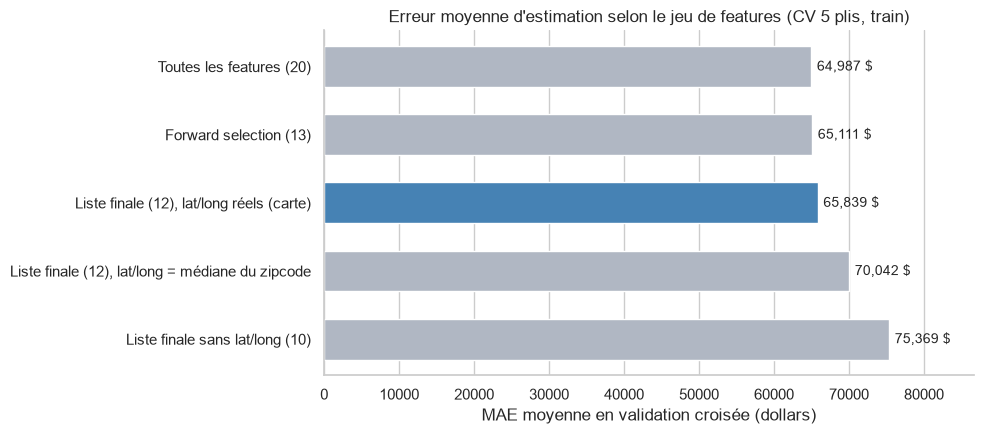

In [20]:
NOM_LISTE_FINALE = "Liste finale (12), lat/long réels (carte)"
mae_par_jeu = validation_jeux["MAE ($)"]
couleurs = ["steelblue" if nom == NOM_LISTE_FINALE else "#b0b7c3" for nom in mae_par_jeu.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
barres = ax.barh(mae_par_jeu.index, mae_par_jeu.to_numpy(), color=couleurs, height=0.6)
ax.invert_yaxis()  # même ordre que le tableau, de haut en bas
ax.bar_label(barres, labels=[f"{v:,.0f} $" for v in mae_par_jeu], padding=4, fontsize=10)
ax.set_xlim(0, mae_par_jeu.max() * 1.15)
ax.set_xlabel("MAE moyenne en validation croisée (dollars)")
ax.set_title("Erreur moyenne d'estimation selon le jeu de features (CV 5 plis, train)", fontsize=12)
ax.grid(axis="y", visible=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

**Lecture des résultats :**
- **La liste finale coûte très peu :** sa MAE est de 65 839 $, contre 64 987 $ avec les 20 features (+852 $, soit +1,3 %), pour un R² de 0,899 contre 0,903. Retirer 8 features, dont toutes celles qu'on ne peut pas saisir, ne dégrade presque pas le modèle.
- **`lat`/`long` sont décisives :** sans elles, la MAE monte à 75 369 $ (+9 530 $, soit +14 %). Le code postal seul ne suffit pas, car le prix varie fortement à l'intérieur d'une même zone (rue calme ou passante, proximité d'un lac…).
- **La médiane du zipcode est un repli acceptable :** 70 042 $, ce qui récupère environ la moitié de la perte. D'où le choix d'une carte où l'utilisateur clique sur l'emplacement exact, avec la médiane comme valeur par défaut.

> Ces scores sont mesurés avec un `HistGradientBoostingRegressor` par défaut, non optimisé. Ils servent à **comparer des jeux de features** entre eux, pas à annoncer la performance finale, qui sera mesurée une seule fois sur le test (section 6).

### 3.7 Sauvegarde de la table zipcode -> lat/long (pour l'application)

**Quoi :** on calcule, pour chaque code postal, la **médiane de `lat` et `long` sur le train**, et on la sauvegarde dans `models/zipcode_latlong.csv`.

**Pourquoi :**
- Dans l'application, la carte Leaflet sera **centrée sur ce point** quand l'utilisateur choisit un code postal. Si l'utilisateur ne clique pas sur la carte, ce point servira de **valeur de repli** pour `lat`/`long`.
- On utilise la **médiane** plutôt que la moyenne : elle est robuste aux quelques maisons excentrées d'une zone, et elle tombe toujours dans une zone habitée.
- Le calcul se fait sur le **train uniquement**, comme tout ce qui apprend des données. La table fait partie du « modèle » au même titre que l'encodeur, d'où son enregistrement dans `models/`.

In [21]:
CHEMIN_ZIP_LATLONG = "../models/zipcode_latlong.csv"

zipcode_latlong = (
    X_train.groupby("zipcode")[["lat", "long"]]
    .median()
    .reset_index()
)
assert zipcode_latlong["zipcode"].nunique() == X["zipcode"].nunique(), "Un code postal du dataset est absent du train"

zipcode_latlong.to_csv(CHEMIN_ZIP_LATLONG, index=False)
print(f"{len(zipcode_latlong)} codes postaux sauvegardés dans {CHEMIN_ZIP_LATLONG}")
display(zipcode_latlong.head())

70 codes postaux sauvegardés dans ../models/zipcode_latlong.csv


,zipcode,lat,long
0,98001,47.31540,-122.2720
1,98002,47.30560,-122.2140
2,98003,47.32775,-122.3080
3,98004,47.62090,-122.2040
4,98005,47.60280,-122.1685


## 4. Entraînement et comparaison des modèles

**Objectif :** comparer quatre algorithmes de régression sur les 12 features retenues (`FEATURES_FINALES`), dans des conditions identiques, pour choisir celui qu'on optimisera en section 5.

**Règle :** tout se passe **sur le train**, par validation croisée. Le jeu de test reste intact jusqu'à la section 6.

### 4.1 Pipelines de préparation et modèles

**Quoi :** pour chaque modèle, on construit un `Pipeline` scikit-learn en deux étapes :
1. **préparation** (`ColumnTransformer`) :
   - `zipcode` : `TargetEncoder` (même configuration qu'en 3.1), suivi d'un `StandardScaler` ;
   - les 11 autres features numériques : `StandardScaler` ;
2. **le modèle**.

**Pourquoi un `Pipeline` :** la préparation fait partie du modèle. À chaque pli de validation croisée, le pipeline est **réajusté sur la partie apprentissage du pli uniquement**, puis appliqué à la partie validation. L'encodage de `zipcode` et les moyennes et écarts-types du scaling ne voient donc jamais les données de validation, et il n'y a aucune fuite. C'est aussi ce même objet unique qui sera sauvegardé avec `joblib` et chargé par l'application Flask : il recevra les données brutes du formulaire et fera lui-même l'encodage et le scaling.

**Pourquoi le scaling (`StandardScaler`) :**
- **Indispensable pour Ridge**, et utile pour LinearRegression. Ridge pénalise la taille des coefficients (`alpha × somme des coefficients²`). Sans mise à l'échelle, une feature exprimée en grands nombres (`sqft_lot`, jusqu'à 1,6 million de sqft) aurait un coefficient minuscule et presque pas pénalisé, alors qu'une feature en petits nombres (`waterfront`, 0 ou 1) serait fortement pénalisée. Centrer et réduire chaque feature (moyenne 0, écart-type 1) met toutes les features sur un pied d'égalité. Pour LinearRegression, les prédictions sont identiques avec ou sans scaling, mais les coefficients deviennent **comparables entre eux**.
- **Sans effet pour les arbres** (Random Forest, Gradient Boosting). Un arbre coupe sur des seuils (« `sqft_living` > 2 000 ? »). Multiplier ou décaler une feature déplace le seuil, mais ne change pas l'ordre des maisons, donc les coupures et les prédictions restent les mêmes. On garde le scaling dans tous les pipelines pour que les quatre modèles reçoivent exactement la même préparation.

**Les quatre modèles** (principes détaillés dans la veille technologique du README) :
- **LinearRegression (baseline)** : elle cherche les coefficients d'une relation linéaire `log(prix) = b0 + b1·x1 + …` qui minimisent l'erreur quadratique. C'est simple et interprétable, mais elle ne capte ni les effets non linéaires ni les interactions. C'est le point de référence : un modèle plus complexe doit faire mieux qu'elle.
- **Ridge (`alpha=1.0`)** : une régression linéaire avec une pénalité L2 sur les coefficients, qui les rétrécit vers 0. Cela stabilise le modèle quand des features sont corrélées entre elles (`sqft_living` et `grade`, r = 0,76). Elle reste linéaire.
- **RandomForestRegressor (`n_estimators=200`)** : il moyenne 200 arbres de décision profonds, chacun entraîné sur un échantillon *bootstrap* des données et sur un sous-ensemble aléatoire de features à chaque coupure. La moyenne réduit la variance des arbres individuels. Il capte naturellement les non-linéarités et les interactions.
- **GradientBoostingRegressor** : il construit des arbres peu profonds (profondeur 3, 100 arbres par défaut) **séquentiellement**, chacun corrigeant les erreurs résiduelles des précédents (descente de gradient sur la fonction de perte). Il est souvent le plus précis sur des données tabulaires, au prix de plus d'hyperparamètres à régler.

In [22]:
# zipcode est encodé à part ; toutes les autres features finales sont numériques
FEATURES_NUMERIQUES = [f for f in FEATURES_FINALES if f != "zipcode"]


def creer_pipeline(modele):
    """Pipeline complet : encodage de zipcode + mise à l'échelle, puis le modèle."""
    preparation = ColumnTransformer([
        ("zipcode", Pipeline([
            ("target_encoding", TargetEncoder(
                target_type="continuous",
                cv=KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE),
            )),
            ("scaling", StandardScaler()),
        ]), ["zipcode"]),
        ("numeriques", StandardScaler(), FEATURES_NUMERIQUES),
    ])
    return Pipeline([("preparation", preparation), ("modele", modele)])


modeles = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "RandomForest": RandomForestRegressor(n_estimators=200, n_jobs=-1, random_state=RANDOM_STATE),
    "GradientBoosting": GradientBoostingRegressor(random_state=RANDOM_STATE),
}
pipelines = {nom: creer_pipeline(modele) for nom, modele in modeles.items()}

# Les modèles ne voient que les 12 features finales
X_train_final = X_train[FEATURES_FINALES]
print(f"Train utilisé : {X_train_final.shape[0]} lignes x {X_train_final.shape[1]} features")
pipelines["Ridge"]

Train utilisé : 17277 lignes x 12 features


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preparation', ...), ('modele', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('zipcode', ...), ('numeriques', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, defaul

### 4.2 Évaluation par validation croisée (5 plis)

**Quoi :** pour chaque pipeline, `cross_val_predict` avec un `KFold` à 5 plis mélangés (`random_state=RANDOM_STATE`). Chaque maison du train reçoit une prédiction faite par un modèle **qui ne l'a pas vue à l'entraînement**. On calcule ensuite :
- **MAE et RMSE en dollars**, après retour à l'échelle des prix avec `np.expm1` (le modèle prédit `log(1 + prix)`) ;
- **le R² sur `log(price)`**, l'échelle sur laquelle le modèle est entraîné ;
- **le temps** de la validation croisée, soit 5 entraînements et 5 prédictions.

**Pourquoi ces métriques :**
- **MAE** (erreur absolue moyenne) : « en moyenne, l'estimation se trompe de X $ ». C'est la plus parlante pour un utilisateur, et c'est notre critère principal.
- **RMSE** (racine de l'erreur quadratique moyenne) : elle pénalise davantage les grosses erreurs. Un écart important entre RMSE et MAE signale quelques erreurs très fortes, typiquement sur les maisons de luxe.
- **R²** : la part de la variance du log-prix expliquée par le modèle (1 = parfait, 0 = pas mieux que la moyenne). Calculé en log, il n'est pas écrasé par les quelques maisons à plusieurs millions.
- **Le temps** : à performance proche, un modèle plus rapide est plus simple à optimiser (section 5) et à réentraîner.

`cross_val_predict` (plutôt que `cross_val_score`) donne une prédiction pour **chaque** maison : on peut ainsi calculer les métriques en dollars et tracer le graphique réel / prédit en 4.4, toujours sans toucher au test.

In [23]:
plis_cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
prix_reel = np.expm1(y_train)

predictions_cv = {}  # prédictions en dollars, réutilisées en 4.4
resultats_cv = []
for nom, pipeline in pipelines.items():
    debut = time.perf_counter()
    log_predit = cross_val_predict(pipeline, X_train_final, y_train, cv=plis_cv)
    duree = time.perf_counter() - debut

    prix_predit = np.expm1(log_predit)
    predictions_cv[nom] = prix_predit
    resultats_cv.append({
        "modèle": nom,
        "MAE ($)": mean_absolute_error(prix_reel, prix_predit),
        "RMSE ($)": np.sqrt(mean_squared_error(prix_reel, prix_predit)),
        "R² (log)": r2_score(y_train, log_predit),
        "temps CV (s)": duree,
    })
    print(f"{nom:<17} terminé en {duree:5.1f} s")

LinearRegression  terminé en   0.2 s
Ridge             terminé en   0.3 s
RandomForest      terminé en  16.4 s
GradientBoosting  terminé en  12.0 s


### 4.3 Tableau comparatif

**Quoi :** les quatre modèles triés par MAE croissante, puis un graphique en barres de la MAE. Le meilleur modèle est mis en évidence.

**Pourquoi :** le tableau donne toutes les métriques côte à côte. Le graphique montre l'ampleur des écarts, ce qui permet de voir si le meilleur modèle se détache nettement ou de peu.

,MAE ($),RMSE ($),R² (log),temps CV (s)
modèle,,,,
RandomForest,"69,358 $","131,716 $",0.8875,16.4 s
GradientBoosting,"71,540 $","130,295 $",0.8866,12.0 s
Ridge,"86,085 $","194,258 $",0.8553,0.3 s
LinearRegression,"86,087 $","194,289 $",0.8553,0.2 s


Meilleur modèle (MAE la plus basse) : RandomForest


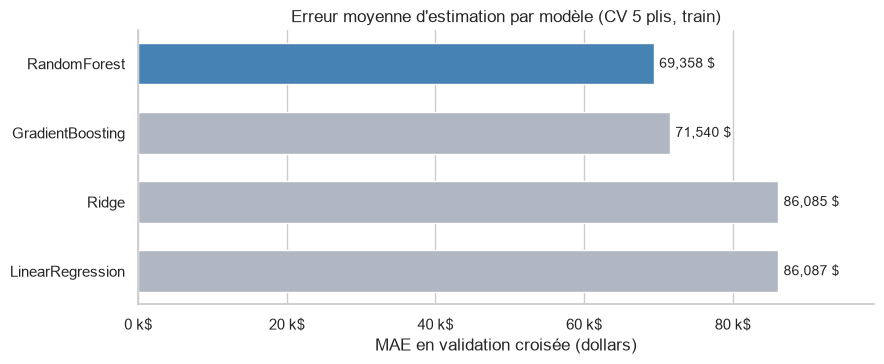

In [24]:
comparatif_modeles = pd.DataFrame(resultats_cv).set_index("modèle").sort_values("MAE ($)")
MEILLEUR_MODELE = comparatif_modeles.index[0]

display(comparatif_modeles.style.format({
    "MAE ($)": "{:,.0f} $", "RMSE ($)": "{:,.0f} $", "R² (log)": "{:.4f}", "temps CV (s)": "{:.1f} s",
}))
print(f"Meilleur modèle (MAE la plus basse) : {MEILLEUR_MODELE}")

mae_modeles = comparatif_modeles["MAE ($)"]
couleurs = ["steelblue" if nom == MEILLEUR_MODELE else "#b0b7c3" for nom in mae_modeles.index]

fig, ax = plt.subplots(figsize=(9, 3.8))
barres = ax.barh(mae_modeles.index, mae_modeles.to_numpy(), color=couleurs, height=0.6)
ax.invert_yaxis()  # meilleur modèle en haut, comme dans le tableau
ax.bar_label(barres, labels=[f"{v:,.0f} $" for v in mae_modeles], padding=4, fontsize=10)
ax.set_xlim(0, mae_modeles.max() * 1.15)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f} k$"))
ax.set_xlabel("MAE en validation croisée (dollars)")
ax.set_title("Erreur moyenne d'estimation par modèle (CV 5 plis, train)", fontsize=12)
ax.grid(axis="y", visible=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

### 4.4 Prix réel vs prix prédit (meilleur modèle)

**Quoi :** pour le meilleur modèle, on place chaque maison du train selon son prix réel (en abscisse) et le prix prédit en validation croisée (en ordonnée). La diagonale `y = x` représente une prédiction parfaite.

**Pourquoi :** une métrique moyenne cache la **structure des erreurs**. Ce graphique montre si le modèle se trompe partout pareil, ou s'il sous-estime systématiquement les maisons chères (points sous la diagonale à droite), un défaut fréquent. Les deux axes sont en **échelle logarithmique** : les prix vont de 75 000 $ à 7,7 M$, et une échelle linéaire écraserait 95 % des maisons dans un coin. Sur cette échelle, l'écart vertical à la diagonale représente une erreur **relative** (en %).

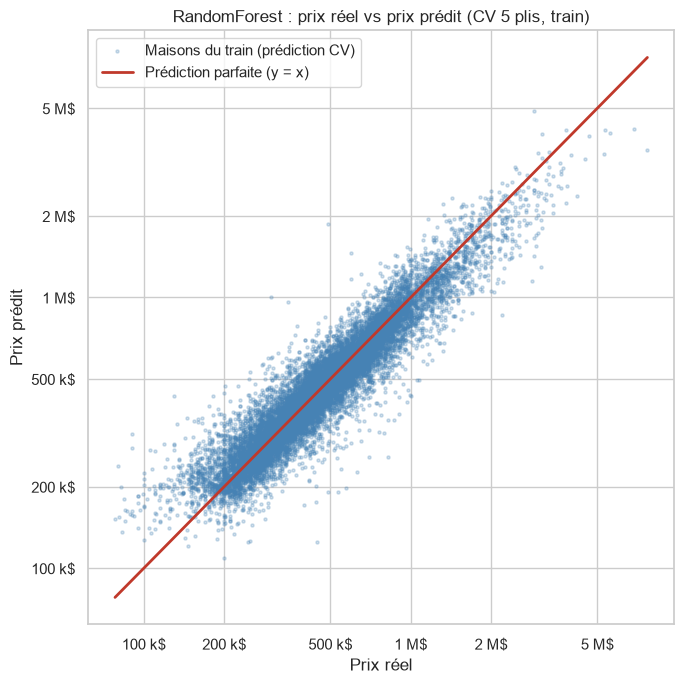

Erreur relative médiane : 8.7%
Maisons estimées à moins de 10 % près : 54.9%
Maisons estimées à moins de 20 % près : 80.9%


,prix réel médian,écart relatif médian (prédit - réel)
tranche,,
20 % les moins chères,"246,000 $",+4.8%
2e quintile,"349,000 $",+0.1%
3e quintile,"450,000 $",+0.2%
4e quintile,"595,000 $",-2.6%
20 % les plus chères,"887,750 $",-5.2%


In [25]:
prix_predit_meilleur = predictions_cv[MEILLEUR_MODELE]
erreur_relative = np.abs(prix_predit_meilleur - prix_reel) / prix_reel

fig, ax = plt.subplots(figsize=(7, 7))
ax.scatter(prix_reel, prix_predit_meilleur, s=5, alpha=0.25, color="steelblue", label="Maisons du train (prédiction CV)")
bornes = [min(prix_reel.min(), prix_predit_meilleur.min()), max(prix_reel.max(), prix_predit_meilleur.max())]
ax.plot(bornes, bornes, color="#c0392b", linewidth=2, label="Prédiction parfaite (y = x)")
ax.set_xscale("log")
ax.set_yscale("log")
graduations = [1e5, 2e5, 5e5, 1e6, 2e6, 5e6]
etiquettes = ["100 k$", "200 k$", "500 k$", "1 M$", "2 M$", "5 M$"]
ax.set_xticks(graduations, etiquettes)
ax.set_yticks(graduations, etiquettes)
ax.minorticks_off()
ax.set_xlabel("Prix réel")
ax.set_ylabel("Prix prédit")
ax.set_title(f"{MEILLEUR_MODELE} : prix réel vs prix prédit (CV 5 plis, train)", fontsize=12)
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

print(f"Erreur relative médiane : {np.median(erreur_relative):.1%}")
print(f"Maisons estimées à moins de 10 % près : {(erreur_relative < 0.10).mean():.1%}")
print(f"Maisons estimées à moins de 20 % près : {(erreur_relative < 0.20).mean():.1%}")

# Biais par tranche de prix : le modèle sous-estime-t-il les maisons chères ?
tranches = pd.qcut(prix_reel, q=5, labels=["20 % les moins chères", "2e quintile", "3e quintile", "4e quintile", "20 % les plus chères"])
biais = (
    pd.DataFrame({
        "prix réel médian": prix_reel,
        "écart relatif médian (prédit - réel)": (prix_predit_meilleur - prix_reel) / prix_reel,
        "tranche": tranches,
    })
    .groupby("tranche", observed=True)
    .median()
)
display(biais.style.format({"prix réel médian": "{:,.0f} $", "écart relatif médian (prédit - réel)": "{:+.1%}"}))

### 4.5 Conclusion et choix du modèle à optimiser

**Quoi :** avant de conclure, on mesure la **taille sur disque** des deux meilleurs pipelines, entraînés sur tout le train et sérialisés avec `joblib` (en mémoire, sans écrire de fichier).

**Pourquoi :** le modèle choisi sera chargé par l'application Flask et embarqué dans l'image Docker. Sa taille conditionne le temps de démarrage, la mémoire consommée et la possibilité de le versionner sur GitHub (limite de 100 Mo par fichier).

In [26]:
for nom in ["RandomForest", "GradientBoosting"]:
    pipeline = creer_pipeline(modeles[nom]).fit(X_train_final, y_train)
    tampon = io.BytesIO()
    joblib.dump(pipeline, tampon)
    print(f"{nom:<17} : {len(tampon.getvalue()) / 1e6:6.1f} Mo une fois sauvegardé")

RandomForest      :  308.3 Mo une fois sauvegardé
GradientBoosting  :    0.1 Mo une fois sauvegardé


**Conclusion de la comparaison :**

- **Les modèles à arbres dominent nettement les modèles linéaires.** Le RandomForest (MAE 69 358 $) et le GradientBoosting (71 540 $) font environ **15 000 $ de mieux** que LinearRegression et Ridge (86 000 $). Leur RMSE est aussi bien plus faible (environ 131 000 $ contre 194 000 $) : les modèles linéaires commettent de très grosses erreurs sur certaines maisons. Comme on l'a vu dans la veille, le prix d'une maison n'est pas une somme d'effets indépendants :
  - **la localisation** agit de façon non linéaire. `lat` et `long` n'ont pas d'effet « plus au nord = plus cher » constant : ce sont des **zones** chères ou bon marché, que les arbres découpent et qu'une droite ne peut pas représenter ;
  - **les interactions** : un mètre carré supplémentaire vaut beaucoup plus à Bellevue qu'au sud du comté, et une vue sur l'eau n'a pas la même valeur selon la qualité de la maison. Les arbres captent ces interactions naturellement, alors qu'un modèle linéaire attribue à chaque feature un effet unique, partout.
- **Ridge n'apporte rien par rapport à LinearRegression** (86 085 $ contre 86 087 $). Avec 17 000 maisons pour 12 features et peu de colinéarité restante après la sélection, il n'y a presque rien à régulariser : `alpha=1.0` est négligeable.
- **Le RandomForest est le meilleur en MAE**, mais de peu : 2 182 $ d'écart avec le GradientBoosting (3 %). Le GradientBoosting a même une RMSE légèrement plus basse (130 295 $ contre 131 716 $) et un R² quasi identique (0,8866 contre 0,8875).
- **Structure des erreurs (4.4) :** l'erreur médiane est de 8,7 %, et 81 % des maisons sont estimées à moins de 20 % près. Le modèle **surestime légèrement les maisons bon marché** (+4,8 %) et **sous-estime les plus chères** (-5,2 %). C'est le « retour vers la moyenne » classique des modèles de régression : les prix extrêmes sont tirés vers le centre.

**Modèle optimisé en section 5 : le GradientBoosting**, bien qu'il soit 2ᵉ en MAE avec ses paramètres par défaut :
1. **La plus grande marge de progression.** Ses réglages par défaut sont très prudents (100 arbres de profondeur 3, taux d'apprentissage 0,1). Le RandomForest, lui, utilise déjà des arbres de profondeur illimitée : l'optimisation a peu à lui apporter. En 3.6, un modèle de boosting non optimisé (`HistGradientBoostingRegressor`) atteignait déjà 65 839 $ de MAE sur les mêmes features, mieux que le RandomForest ici.
2. **Le déploiement.** Une fois sauvegardé, le RandomForest pèse environ **300 Mo**, contre **moins de 1 Mo** pour le GradientBoosting (cellule ci-dessus). C'est trop lourd pour un dépôt GitHub (limite de 100 Mo par fichier) et coûteux pour l'image Docker et le temps de démarrage de l'application.
3. **Le coût du grid search.** Il est plus rapide à entraîner (environ 9 s contre 13 s pour la validation croisée), ce qui permet d'explorer plus de combinaisons d'hyperparamètres.

Le RandomForest reste la **référence à battre** : si le GradientBoosting optimisé ne fait pas mieux que 69 358 $ de MAE en validation croisée, on reconsidérera ce choix en section 5.

## 5. Optimisation du GradientBoosting par grid search

**Objectif :** trouver les hyperparamètres du GradientBoosting qui minimisent l'erreur, toujours **sur le train uniquement**.

### 5.1 Principe du grid search et hyperparamètres testés

**Le grid search avec validation croisée :** on définit une **grille** de valeurs pour chaque hyperparamètre, puis `GridSearchCV` teste **toutes les combinaisons**. Chaque combinaison est évaluée par validation croisée : le train est découpé en *k* plis, le modèle est entraîné sur *k − 1* plis et évalué sur le pli restant, *k* fois, et on garde la moyenne. La combinaison qui a la meilleure moyenne est retenue. La validation croisée évite de choisir des hyperparamètres qui marchent par chance sur un seul découpage, et le jeu de test n'intervient jamais dans ce choix.

**Rappel du fonctionnement du boosting** (voir la veille du README) : le GradientBoosting construit des arbres **les uns après les autres**. Chaque nouvel arbre est entraîné à prédire les **erreurs résiduelles** des arbres précédents, et sa prédiction est ajoutée au total, multipliée par un petit facteur. Le modèle se corrige donc progressivement.

**Rôle de chaque hyperparamètre testé :**

| Hyperparamètre | Rôle dans le boosting | Valeurs testées |
|---|---|---|
| `n_estimators` | Nombre d'arbres, donc d'étapes de correction. Trop peu : le modèle n'a pas fini d'apprendre (sous-apprentissage). Beaucoup : il peut finir par apprendre le bruit. | 300, 600 (contre 100 par défaut) |
| `learning_rate` | Le facteur appliqué à chaque arbre (*shrinkage*). Petit : chaque arbre corrige un peu, l'apprentissage est plus lent mais plus fin et généralise mieux, et il faut plus d'arbres. Il est **lié à `n_estimators`** : on les règle ensemble. | 0,05 et 0,1 |
| `max_depth` | Profondeur de chaque arbre, donc l'ordre des **interactions** captées. Une profondeur de 3 combine au plus 3 features par branche. Plus profond, l'arbre capte des interactions plus riches (localisation × surface × qualité), avec un risque de surapprentissage. | 4 et 6 (contre 3 par défaut) |
| `subsample` | Part du train, tirée au hasard, utilisée pour construire chaque arbre (*stochastic gradient boosting*). Une valeur inférieure à 1 ajoute de l'aléa qui **régularise** (les arbres sont moins corrélés entre eux) et accélère l'entraînement. | 0,8 et 1,0 |

### 5.2 Grid search

**Quoi :** `GridSearchCV` sur le **pipeline complet** de la section 4 (encodage de `zipcode` + scaling + GradientBoosting), avec 2 × 2 × 2 × 2 = **16 combinaisons**, `cv=KFold(3, shuffle=True, random_state=RANDOM_STATE)`, `scoring="neg_mean_absolute_error"` et `n_jobs=-1`.

**Pourquoi ces choix :**
- **Le pipeline complet, pas le modèle seul :** à chaque pli, le `TargetEncoder` et le `StandardScaler` sont réajustés sur la partie apprentissage du pli. La recherche est donc sans fuite. Les hyperparamètres sont désignés par `modele__<nom>` (nom de l'étape + nom du paramètre).
- **`cv=3` plutôt que 5 :** le grid search entraîne `combinaisons × plis` modèles, soit 48 avec 3 plis contre 80 avec 5, et les modèles à 600 arbres de profondeur 6 sont longs à entraîner. 3 plis de plus de 11 000 maisons donnent une estimation déjà stable pour **classer** les combinaisons. La comparaison finale (5.4) se fera ensuite à 5 plis, avec le même protocole qu'en section 4.
- **Une grille réduite (2 valeurs par paramètre) :** le nombre de combinaisons est multiplié par le nombre de valeurs de chaque paramètre. Avec 4 valeurs chacun, on passerait à 256 combinaisons. Les valeurs sont choisies **autour des réglages par défaut, dans la direction suggérée par la section 4** : le GradientBoosting par défaut (100 arbres, profondeur 3) est probablement trop simple, donc on teste plus d'arbres et plus de profondeur.
- **`neg_mean_absolute_error` :** on optimise la MAE, notre critère principal. Scikit-learn maximise toujours le score, d'où le signe négatif. La MAE est calculée ici sur `log(price)`, ce qui revient à une erreur **relative** moyenne : c'est cohérent avec l'entraînement en log.
- **`n_jobs=-1`** : les 48 entraînements sont répartis sur tous les cœurs du processeur.
- **`refit=False`** : on réentraînera nous-mêmes le modèle final sur tout le train en 6.1, de façon explicite.

In [27]:
grille = {
    "modele__n_estimators": [300, 600],
    "modele__learning_rate": [0.05, 0.1],
    "modele__max_depth": [4, 6],
    "modele__subsample": [0.8, 1.0],
}

grid_search = GridSearchCV(
    creer_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)),
    param_grid=grille,
    cv=KFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE),
    scoring="neg_mean_absolute_error",
    n_jobs=-1,
    refit=False,
)

nb_combinaisons = np.prod([len(valeurs) for valeurs in grille.values()])
print(f"{nb_combinaisons} combinaisons x 3 plis = {nb_combinaisons * 3} entraînements")

debut = time.perf_counter()
grid_search.fit(X_train_final, y_train)
duree_grid = time.perf_counter() - debut
print(f"Temps total du grid search : {duree_grid / 60:.1f} min ({duree_grid:.0f} s)")

16 combinaisons x 3 plis = 48 entraînements
Temps total du grid search : 1.8 min (109 s)


### 5.3 Meilleures combinaisons

**Quoi :** les 10 meilleures combinaisons, classées par MAE moyenne sur les 3 plis (en log-prix, convertie en erreur relative approximative), avec leur écart-type et leur temps d'entraînement moyen.

**Pourquoi :** regarder le **haut du classement**, et pas seulement le vainqueur, montre quels hyperparamètres comptent vraiment. Si les meilleures combinaisons partagent une même valeur, ce réglage est déterminant. Si les écarts entre elles sont inférieurs à l'écart-type, plusieurs réglages se valent, et on peut préférer le plus rapide.

In [28]:
resultats_grid = pd.DataFrame(grid_search.cv_results_)
colonnes_params = [f"param_{p}" for p in grille]

top10 = (
    resultats_grid.sort_values("rank_test_score")
    .head(10)[["rank_test_score", *colonnes_params, "mean_test_score", "std_test_score", "mean_fit_time"]]
    .rename(columns={p: p.replace("param_modele__", "") for p in colonnes_params})
    .rename(columns={"rank_test_score": "rang", "std_test_score": "écart-type", "mean_fit_time": "temps moyen (s)"})
)
top10["MAE log"] = -top10.pop("mean_test_score")
# exp(MAE log) - 1 ≈ erreur relative typique en %
top10["≈ erreur relative"] = np.expm1(top10["MAE log"])
top10 = top10.set_index("rang")[["n_estimators", "learning_rate", "max_depth", "subsample",
                                 "MAE log", "écart-type", "≈ erreur relative", "temps moyen (s)"]]

display(top10.style.format({"MAE log": "{:.4f}", "écart-type": "{:.4f}",
                            "≈ erreur relative": "{:.2%}", "temps moyen (s)": "{:.1f}"}))

MEILLEURS_PARAMS = grid_search.best_params_
print("Meilleurs hyperparamètres :")
for nom, valeur in MEILLEURS_PARAMS.items():
    print(f"  {nom.replace('modele__', ''):<14} = {valeur}")

,n_estimators,learning_rate,max_depth,subsample,MAE log,écart-type,≈ erreur relative,temps moyen (s)
rang,,,,,,,,
1,600,0.050000,6,0.800000,0.1179,0.0006,12.51%,24.0
2,300,0.050000,6,0.800000,0.1185,0.0006,12.58%,11.2
3,600,0.050000,6,1.000000,0.1192,0.0009,12.66%,28.5
4,600,0.050000,4,0.800000,0.1195,0.0010,12.69%,16.1
5,600,0.100000,4,0.800000,0.1196,0.0008,12.70%,15.9
6,300,0.100000,6,0.800000,0.1196,0.0009,12.71%,11.8
7,300,0.050000,6,1.000000,0.1197,0.0009,12.72%,14.1
8,300,0.100000,6,1.000000,0.1197,0.0012,12.72%,13.4
9,300,0.100000,4,0.800000,0.1204,0.0006,12.79%,7.6


Meilleurs hyperparamètres :
  learning_rate  = 0.05
  max_depth      = 6
  n_estimators   = 600
  subsample      = 0.8


**Lecture du grid search :**
- **Meilleure combinaison :** 600 arbres, `learning_rate=0.05`, `max_depth=6`, `subsample=0.8`. Sa MAE est de 0,118 en log, soit une erreur relative typique d'environ 12,5 %.
- **Le réglage déterminant est `subsample=0.8` :** il est présent dans 5 des 6 premières combinaisons. Le sous-échantillonnage aléatoire régularise bien le modèle. Viennent ensuite **la profondeur 6**, qui capte des interactions plus riches que la profondeur 3 par défaut, et le couple **petit `learning_rate` + beaucoup d'arbres**, qui donne un apprentissage plus fin.
- **Les écarts en tête sont faibles.** La 2ᵉ combinaison (300 arbres) est à 0,0006 de la 1ʳᵉ, l'équivalent d'un écart-type, et elle est **deux fois plus rapide** (11 s contre 24 s). Les deux se valent statistiquement. On garde la 1ʳᵉ, car le temps d'entraînement (une demi-minute) n'est pas une contrainte ici.
- **Limite :** le meilleur réglage se trouve **au bord de la grille** pour trois paramètres (600 arbres, profondeur 6, `learning_rate` 0,05). Une grille élargie (plus d'arbres, profondeur 8, `learning_rate` 0,02) pourrait encore améliorer légèrement le modèle (voir les pistes en section 7).

### 5.4 Comparaison finale en validation croisée 5 plis

**Quoi :** on compare trois modèles **avec exactement le même protocole qu'en section 4** (`cross_val_predict`, `KFold` à 5 plis avec `random_state=RANDOM_STATE`, MAE et RMSE en dollars, R² en log) :
- le GradientBoosting **par défaut** (section 4) ;
- le GradientBoosting **optimisé** (meilleurs paramètres du grid search) ;
- le RandomForest, la **référence à battre** (section 4).

**Pourquoi refaire une CV à 5 plis :** le score du grid search est **légèrement optimiste**. Parmi 16 combinaisons, la meilleure a pu profiter d'un peu de chance sur ces 3 plis précis. Une évaluation sur un **autre découpage** (5 plis), identique à celui de la section 4, donne une comparaison équitable avec les deux autres modèles. Les plis étant les mêmes qu'en section 4, on **réutilise** les prédictions déjà calculées pour le GradientBoosting par défaut et le RandomForest.

CV 5 plis du modèle optimisé : 25 s (en parallèle)


,MAE ($),RMSE ($),R² (log)
GradientBoosting optimisé,"63,478 $","114,462 $",0.9021
RandomForest (référence),"69,358 $","131,716 $",0.8875
GradientBoosting par défaut,"71,540 $","130,295 $",0.8866


Gain de l'optimisation (MAE) : 8,062 $
Écart avec le RandomForest (MAE, positif = optimisé meilleur) : 5,879 $


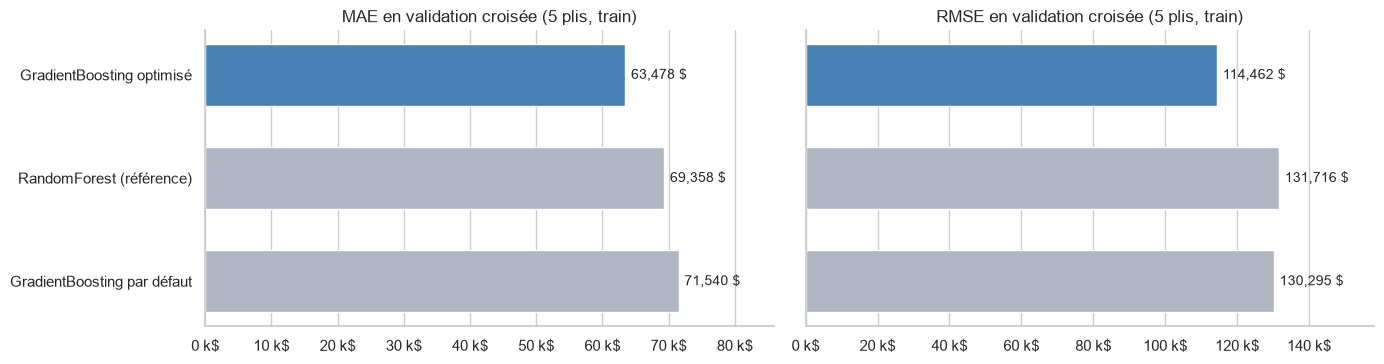

In [29]:
pipeline_optimise = creer_pipeline(GradientBoostingRegressor(random_state=RANDOM_STATE)).set_params(**MEILLEURS_PARAMS)

debut = time.perf_counter()
log_predit_optimise = cross_val_predict(pipeline_optimise, X_train_final, y_train, cv=plis_cv, n_jobs=-1)
duree_optimise = time.perf_counter() - debut
predictions_cv["GradientBoosting optimisé"] = np.expm1(log_predit_optimise)

# Même protocole qu'en section 4 : métriques en dollars, R² en log
resultat_optimise = {
    "MAE ($)": mean_absolute_error(prix_reel, np.expm1(log_predit_optimise)),
    "RMSE ($)": np.sqrt(mean_squared_error(prix_reel, np.expm1(log_predit_optimise))),
    "R² (log)": r2_score(y_train, log_predit_optimise),
}
comparaison_finale = pd.DataFrame({
    "GradientBoosting par défaut": comparatif_modeles.loc["GradientBoosting", ["MAE ($)", "RMSE ($)", "R² (log)"]],
    "GradientBoosting optimisé": pd.Series(resultat_optimise),
    "RandomForest (référence)": comparatif_modeles.loc["RandomForest", ["MAE ($)", "RMSE ($)", "R² (log)"]],
}).T.sort_values("MAE ($)")
print(f"CV 5 plis du modèle optimisé : {duree_optimise:.0f} s (en parallèle)")

display(comparaison_finale.style.format({"MAE ($)": "{:,.0f} $", "RMSE ($)": "{:,.0f} $", "R² (log)": "{:.4f}"}))

gain_vs_defaut = comparaison_finale.loc["GradientBoosting par défaut", "MAE ($)"] - resultat_optimise["MAE ($)"]
ecart_vs_rf = comparaison_finale.loc["RandomForest (référence)", "MAE ($)"] - resultat_optimise["MAE ($)"]
print(f"Gain de l'optimisation (MAE) : {gain_vs_defaut:,.0f} $")
print(f"Écart avec le RandomForest (MAE, positif = optimisé meilleur) : {ecart_vs_rf:,.0f} $")

# Graphique : MAE et RMSE côte à côte (deux graphiques, même unité, échelles séparées)
fig, axes = plt.subplots(1, 2, figsize=(14, 3.8), sharey=True)
for ax, metrique in zip(axes, ["MAE ($)", "RMSE ($)"]):
    valeurs = comparaison_finale[metrique]
    couleurs = ["steelblue" if nom == "GradientBoosting optimisé" else "#b0b7c3" for nom in valeurs.index]
    barres = ax.barh(valeurs.index, valeurs.to_numpy(), color=couleurs, height=0.6)
    ax.bar_label(barres, labels=[f"{v:,.0f} $" for v in valeurs], padding=4, fontsize=10)
    ax.set_xlim(0, valeurs.max() * 1.2)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v / 1000:.0f} k$"))
    ax.set_title(f"{metrique.split()[0]} en validation croisée (5 plis, train)", fontsize=12)
    ax.grid(axis="y", visible=False)
    ax.spines[["top", "right"]].set_visible(False)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

**Conclusion de l'optimisation : le GradientBoosting optimisé bat nettement le RandomForest.**
- **Sa MAE est de 63 478 $**, contre 69 358 $ pour le RandomForest (−5 879 $, soit −8,5 %) et 71 540 $ pour le GradientBoosting par défaut (−8 062 $, soit −11 %).
- **Le gain est encore plus fort sur la RMSE** : 114 462 $ contre 131 716 $ pour le RandomForest (−13 %). Le modèle optimisé commet moins de très grosses erreurs, typiquement sur les maisons chères.
- **Son R² est de 0,902**, contre 0,888 pour le RandomForest.
- La comparaison est **équitable** : même découpage en 5 plis que la section 4, différent des 3 plis du grid search, et toujours sur le train uniquement.

Le pari de la section 4.5 est donc confirmé : les réglages par défaut du GradientBoosting étaient trop prudents. Une fois optimisé, il devient le meilleur modèle, tout en restant léger. **C'est le modèle final.**

## 6. Évaluation finale et sauvegarde

**Objectif :** entraîner le modèle final, mesurer **une seule fois** sa performance sur le jeu de test mis de côté depuis la section 2, puis le sauvegarder pour l'application Flask.

### 6.1 Entraînement du modèle final sur tout le train

**Quoi :** on entraîne le pipeline complet (encodage de `zipcode` + scaling + GradientBoosting avec les meilleurs hyperparamètres) sur **l'ensemble du train** (17 277 maisons).

**Pourquoi tout le train :** en validation croisée, chaque modèle n'a vu que 80 % du train. Maintenant que les choix sont faits (features, modèle, hyperparamètres), on utilise toutes les données disponibles pour le modèle livré : plus de données donnent en général un modèle un peu meilleur. Le test, lui, reste intact.

In [30]:
modele_final = clone(pipeline_optimise)

debut = time.perf_counter()
modele_final.fit(X_train_final, y_train)
print(f"Modèle final entraîné sur {len(X_train_final)} maisons en {time.perf_counter() - debut:.1f} s")
print(f"Hyperparamètres : { {k.replace('modele__', ''): v for k, v in MEILLEURS_PARAMS.items()} }")

Modèle final entraîné sur 17277 maisons en 27.2 s
Hyperparamètres : {'learning_rate': 0.05, 'max_depth': 6, 'n_estimators': 600, 'subsample': 0.8}


### 6.2 Évaluation unique sur le jeu de test

**Quoi :** on prédit le prix des 4 320 maisons du test, que le modèle n'a jamais vues, et on calcule :
- MAE et RMSE **en dollars**, et R² sur `log(price)`, comme en validation croisée ;
- l'**erreur relative médiane** (« l'estimation typique se trompe de X % ») et la part de maisons estimées à moins de 10 % et à moins de 20 % près.

On compare ensuite ces scores à ceux de la validation croisée (5.4).

**Pourquoi une seule fois :** si l'on revenait modifier le modèle après avoir regardé le test, le test deviendrait un jeu de validation de plus, et la performance annoncée ne serait plus une estimation honnête de ce qui arrivera sur de nouvelles maisons. **Comment lire la comparaison :** des scores test proches des scores de CV indiquent que le modèle **généralise** et ne surapprend pas. Un test nettement moins bon signalerait que les choix faits sur le train sont trop optimistes.

In [31]:
X_test_final = X_test[FEATURES_FINALES]
prix_reel_test = np.expm1(y_test)
log_predit_test = modele_final.predict(X_test_final)
prix_predit_test = np.expm1(log_predit_test)


def metriques_completes(prix_reel, prix_predit, log_reel, log_predit):
    """Toutes les métriques d'évaluation, en dollars, en log et en erreur relative."""
    erreur_rel = np.abs(prix_predit - prix_reel) / prix_reel
    return {
        "MAE ($)": mean_absolute_error(prix_reel, prix_predit),
        "RMSE ($)": np.sqrt(mean_squared_error(prix_reel, prix_predit)),
        "R² (log)": r2_score(log_reel, log_predit),
        "erreur relative médiane": np.median(erreur_rel),
        "à moins de 10 %": (erreur_rel < 0.10).mean(),
        "à moins de 20 %": (erreur_rel < 0.20).mean(),
    }


METRIQUES_TEST = metriques_completes(prix_reel_test, prix_predit_test, y_test, log_predit_test)
metriques_cv = metriques_completes(prix_reel, predictions_cv["GradientBoosting optimisé"], y_train, log_predit_optimise)

bilan = pd.DataFrame({"validation croisée (train, 5 plis)": metriques_cv, "test (évaluation finale)": METRIQUES_TEST})
formats = {"MAE ($)": "{:,.0f} $", "RMSE ($)": "{:,.0f} $", "R² (log)": "{:.4f}",
           "erreur relative médiane": "{:.1%}", "à moins de 10 %": "{:.1%}", "à moins de 20 %": "{:.1%}"}
display(bilan.apply(lambda ligne: ligne.map(formats[ligne.name].format), axis=1))

,"validation croisée (train, 5 plis)",test (évaluation finale)
MAE ($),"63,478 $","62,238 $"
RMSE ($),"114,462 $","119,825 $"
R² (log),0.9021,0.9041
erreur relative médiane,8.3%,8.0%
à moins de 10 %,57.3%,58.4%
à moins de 20 %,83.2%,84.4%


**Résultat sur le test : le modèle généralise bien, sans surapprentissage.**
- **Sur 4 320 maisons jamais vues, la MAE est de 62 238 $**, avec un R² (log) de 0,904. L'estimation typique se trompe de **8,0 %** (erreur relative médiane). **58 %** des maisons sont estimées à moins de 10 % près, et **84 %** à moins de 20 % près.
- **Les scores du test sont très proches de ceux de la validation croisée**, et même légèrement meilleurs (MAE 62 238 $ contre 63 478 $, R² 0,904 contre 0,902). C'est le signe que le modèle n'a pas surappris le train, et que la démarche (sélection et optimisation sur le train seul) n'a pas produit d'estimation trop optimiste. Le léger mieux s'explique par l'entraînement sur 100 % du train, contre 80 % en validation croisée, et par la variabilité naturelle d'un échantillon de test.
- **Seule la RMSE est un peu plus élevée** (119 825 $ contre 114 462 $). La RMSE est très sensible aux quelques grosses erreurs, et le test contient quelques maisons de luxe (jusqu'à 7 M$) sur lesquelles l'erreur en dollars est forcément importante.

### 6.3 Graphiques sur le test

**Quoi :**
1. **Prix réel vs prix prédit** des maisons du test (axes logarithmiques, comme en 4.4), avec la diagonale de prédiction parfaite.
2. **Distribution de l'erreur relative signée** `(prédit − réel) / réel`, en %. Une valeur positive correspond à une surestimation.

**Pourquoi :** le premier graphique vérifie que le comportement observé en validation croisée (bonne précision au centre, retour vers la moyenne aux extrêmes) se retrouve sur des maisons jamais vues. Le second montre la **forme** des erreurs : un histogramme centré sur 0 signale l'absence de biais global, et la largeur de la cloche indique la précision typique. On visualise aussi la zone de ±10 %.

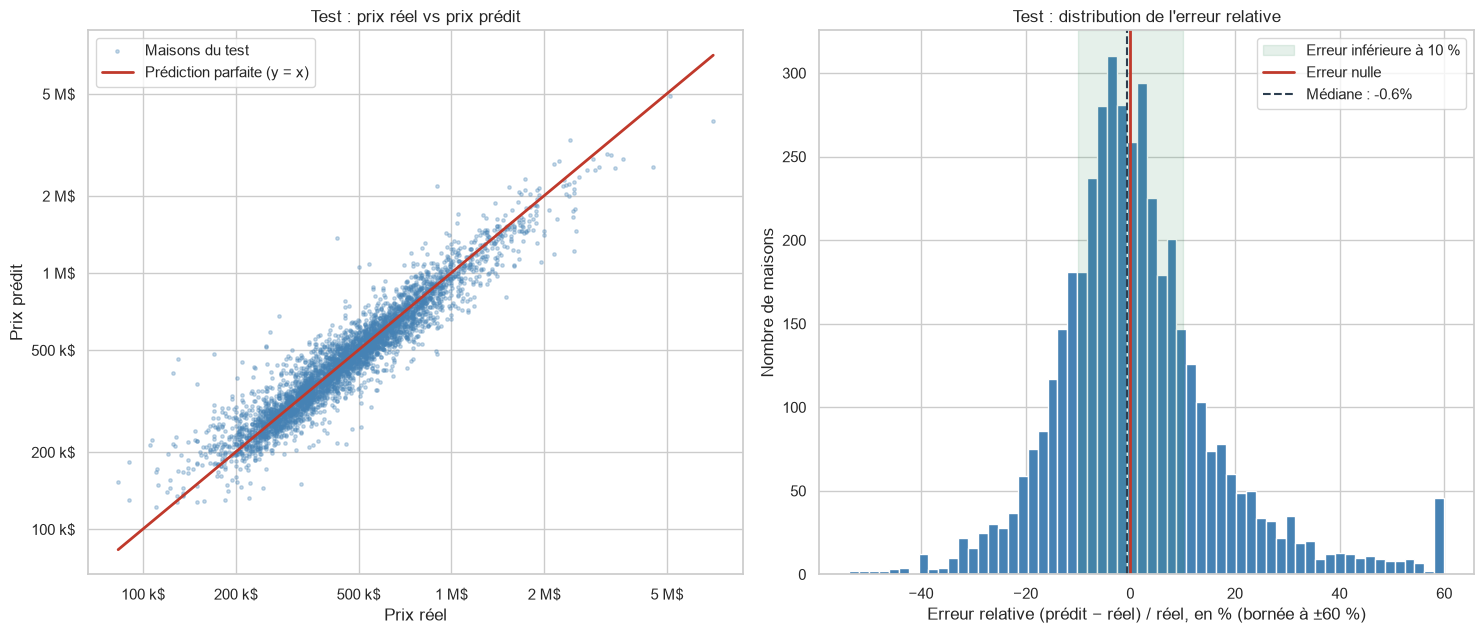

Erreurs au-delà de ±60 % (regroupées aux bords de l'histogramme) : 40 maisons


,prix réel médian,écart relatif médian (prédit - réel)
tranche,,
20 % les moins chères,"246,500 $",+3.3%
2e quintile,"340,500 $",+0.3%
3e quintile,"450,000 $",+0.4%
4e quintile,"589,250 $",-2.6%
20 % les plus chères,"889,950 $",-4.0%


In [32]:
erreur_signee_test = (prix_predit_test - prix_reel_test) / prix_reel_test

fig, axes = plt.subplots(1, 2, figsize=(15, 6.5))

# 1. Réel vs prédit
ax = axes[0]
ax.scatter(prix_reel_test, prix_predit_test, s=6, alpha=0.3, color="steelblue", label="Maisons du test")
bornes = [min(prix_reel_test.min(), prix_predit_test.min()), max(prix_reel_test.max(), prix_predit_test.max())]
ax.plot(bornes, bornes, color="#c0392b", linewidth=2, label="Prédiction parfaite (y = x)")
ax.set_xscale("log")
ax.set_yscale("log")
graduations = [1e5, 2e5, 5e5, 1e6, 2e6, 5e6]
etiquettes = ["100 k$", "200 k$", "500 k$", "1 M$", "2 M$", "5 M$"]
ax.set_xticks(graduations, etiquettes)
ax.set_yticks(graduations, etiquettes)
ax.minorticks_off()
ax.set_xlabel("Prix réel")
ax.set_ylabel("Prix prédit")
ax.set_title("Test : prix réel vs prix prédit", fontsize=12)
ax.legend(loc="upper left")

# 2. Distribution de l'erreur relative
ax = axes[1]
ax.hist(np.clip(erreur_signee_test * 100, -60, 60), bins=60, color="steelblue", edgecolor="white")
ax.axvspan(-10, 10, color="seagreen", alpha=0.12, label="Erreur inférieure à 10 %")
ax.axvline(0, color="#c0392b", linewidth=2, label="Erreur nulle")
ax.axvline(np.median(erreur_signee_test) * 100, color="#2c3e50", linestyle="--", linewidth=1.5,
           label=f"Médiane : {np.median(erreur_signee_test):+.1%}")
ax.set_xlabel("Erreur relative (prédit − réel) / réel, en % (bornée à ±60 %)")
ax.set_ylabel("Nombre de maisons")
ax.set_title("Test : distribution de l'erreur relative", fontsize=12)
ax.legend(loc="upper right")

plt.tight_layout()
plt.show()

print(f"Erreurs au-delà de ±60 % (regroupées aux bords de l'histogramme) : {(np.abs(erreur_signee_test) > 0.6).sum()} maisons")
tranches_test = pd.qcut(prix_reel_test, q=5, labels=["20 % les moins chères", "2e quintile", "3e quintile", "4e quintile", "20 % les plus chères"])
biais_test = (
    pd.DataFrame({"prix réel médian": prix_reel_test, "écart relatif médian (prédit - réel)": erreur_signee_test, "tranche": tranches_test})
    .groupby("tranche", observed=True)
    .median()
)
display(biais_test.style.format({"prix réel médian": "{:,.0f} $", "écart relatif médian (prédit - réel)": "{:+.1%}"}))

**Lecture des graphiques :**
- **Réel vs prédit :** les points suivent étroitement la diagonale sur toute la gamme de 100 k$ à 2 M$. Au-delà de 2 M$, ils passent **sous la diagonale** : les maisons de luxe sont sous-estimées. Elles sont peu nombreuses dans les données, donc peu apprises.
- **Distribution de l'erreur :** la distribution est **centrée sur 0** (médiane −0,6 %), sans biais global, et resserrée : l'essentiel des maisons se trouve dans la zone de ±10 %. On observe une **traîne à droite**, de fortes surestimations, avec 40 maisons à plus de 60 % d'erreur. Ce sont surtout des biens vendus très en dessous de leur valeur apparente (ventes familiales, maisons à rénover, ventes forcées), un contexte que les 12 features ne décrivent pas.
- **Par tranche de prix :** on retrouve le **retour vers la moyenne** observé en 4.4, mais atténué. Les maisons les moins chères sont surestimées de 3,3 % (contre 4,8 % pour le RandomForest), et les plus chères sous-estimées de 4,0 % (contre 5,2 %). Les trois quintiles centraux sont estimés sans biais (entre −2,6 % et +0,4 %).

### 6.4 Importance des features du modèle final

**Quoi :** l'importance de chaque feature dans le GradientBoosting final (`feature_importances_`), c'est-à-dire la part de la réduction totale d'erreur apportée par les coupures sur cette feature, sommée sur tous les arbres.

**Pourquoi :** cela permet de vérifier que le modèle s'appuie sur des variables **sensées** (surface, qualité, localisation) et non sur un artefact, et d'expliquer ses estimations. Limite : cette importance « par impureté » est calculée sur le train, et elle tend à favoriser les variables continues aux nombreuses valeurs possibles. Elle indique **ce que le modèle utilise**, pas un effet causal sur le prix.

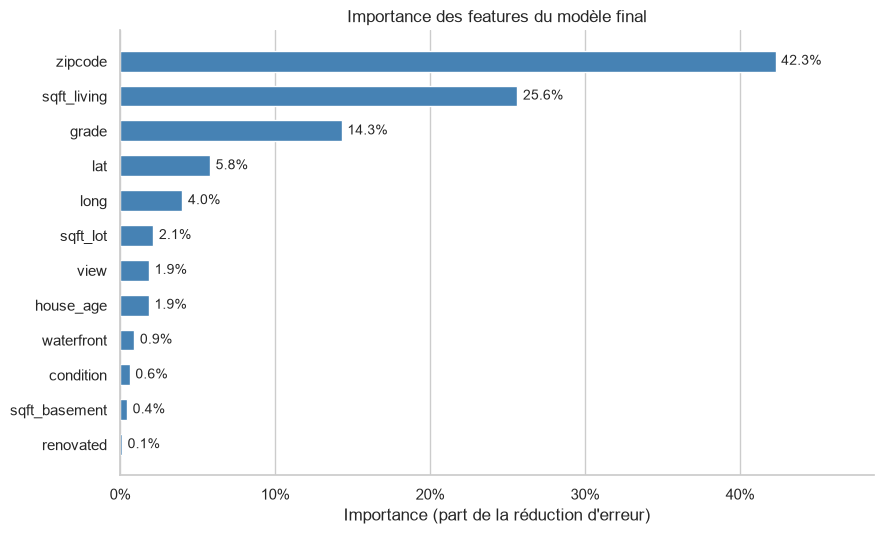

zipcode          42.3%
sqft_living      25.6%
grade            14.3%
lat               5.8%
long              4.0%
sqft_lot          2.1%
view              1.9%
house_age         1.9%
waterfront        0.9%
condition         0.6%
sqft_basement     0.4%
renovated         0.1%


In [33]:
noms_features = [nom.split("__", 1)[1] for nom in modele_final.named_steps["preparation"].get_feature_names_out()]
importances = (
    pd.Series(modele_final.named_steps["modele"].feature_importances_, index=noms_features)
    .sort_values(ascending=True)
)

fig, ax = plt.subplots(figsize=(9, 5.5))
barres = ax.barh(importances.index, importances.to_numpy(), color="steelblue", height=0.6)
ax.bar_label(barres, labels=[f"{v:.1%}" for v in importances], padding=4, fontsize=10)
ax.set_xlim(0, importances.max() * 1.15)
ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:.0%}"))
ax.set_xlabel("Importance (part de la réduction d'erreur)")
ax.set_title("Importance des features du modèle final", fontsize=12)
ax.grid(axis="y", visible=False)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.show()

print(importances.sort_values(ascending=False).map("{:.1%}".format).to_string())

**Interprétation :**
- **La localisation domine : elle porte 52 % de l'importance** (`zipcode` 42 %, `lat` 6 % et `long` 4 %). C'est l'adage de l'immobilier, « l'emplacement, l'emplacement, l'emplacement ». `lat` et `long` affinent le prix moyen de la zone : ils distinguent les quartiers à l'intérieur d'un même code postal. L'importance de `zipcode` est aussi gonflée par construction, car son target encoding résume déjà le niveau de prix de la zone.
- **Viennent ensuite la taille et la qualité de la maison :** `sqft_living` (26 %) et `grade` (14 %). À elles trois avec la localisation, ces variables expliquent plus de 90 % des décisions du modèle.
- **Les autres features apportent des ajustements fins :** `sqft_lot`, `view`, `house_age`, `waterfront` et `condition` pèsent entre 0,6 % et 2 %. Une faible importance moyenne ne signifie pas un faible effet individuel : `waterfront` ne concerne que 0,7 % des maisons, mais pour celles-ci, l'effet sur le prix est très fort.
- **`sqft_basement` (0,4 %) et `renovated` (0,1 %)** sont presque inutilisées. C'est cohérent avec leur rejet par Boruta en 3.3. On les a gardées parce qu'elles sont faciles à saisir et ne dégradent pas le modèle, mais on pourrait les retirer sans perte notable.

Cet ordre (localisation, puis surface, puis qualité) est **conforme à l'intuition** et à l'analyse des corrélations (3.2) : le modèle s'appuie sur des variables sensées.

### 6.5 Sauvegarde du modèle et des métadonnées

**Quoi :**
- `models/model.joblib` : le **pipeline complet** (encodage de `zipcode` + scaling + GradientBoosting), sauvegardé avec `joblib` ;
- `models/metadata.json` : les informations nécessaires à l'application et à la traçabilité (features attendues et dans quel ordre, codes postaux connus, versions de Python et de scikit-learn, hyperparamètres, métriques test, date d'entraînement).

**Pourquoi :**
- Sauvegarder le **pipeline entier**, et pas seulement le modèle, garantit que l'application applique **exactement** la même préparation qu'à l'entraînement. Flask passe les 12 features brutes, et le pipeline encode, met à l'échelle et prédit.
- `joblib` est le format recommandé par scikit-learn pour les objets contenant de gros tableaux NumPy.
- Un fichier `joblib` ne se recharge de façon fiable qu'avec la **même version de scikit-learn** : d'où l'enregistrement des versions dans les métadonnées (et dans `requirements.txt`). La **liste des codes postaux** sert à proposer au formulaire uniquement ceux que le modèle connaît. Les **métriques** et la **date** permettent d'afficher la précision du modèle dans l'application.

In [34]:
CHEMIN_MODELE = "../models/model.joblib"
CHEMIN_METADONNEES = "../models/metadata.json"

joblib.dump(modele_final, CHEMIN_MODELE)
taille_mo = len(open(CHEMIN_MODELE, "rb").read()) / 1e6
print(f"Pipeline complet sauvegardé dans {CHEMIN_MODELE} ({taille_mo:.2f} Mo)")

metadonnees = {
    "features": FEATURES_FINALES,
    "cible": "log1p(price) : appliquer np.expm1 à la prédiction pour obtenir un prix en dollars",
    "annee_reference_prix": 2015,
    "zipcodes": sorted(int(z) for z in X_train["zipcode"].unique()),
    "modele": "GradientBoostingRegressor",
    "hyperparametres": {k.replace("modele__", ""): v for k, v in MEILLEURS_PARAMS.items()},
    "metriques_test": {nom: round(float(valeur), 4) for nom, valeur in METRIQUES_TEST.items()},
    "versions": {"python": platform.python_version(), "scikit-learn": version("scikit-learn")},
    "nb_maisons_entrainement": int(len(X_train_final)),
    "date_entrainement": datetime.now().isoformat(timespec="seconds"),
}
with open(CHEMIN_METADONNEES, "w", encoding="utf-8") as fichier:
    json.dump(metadonnees, fichier, ensure_ascii=False, indent=2)

print(f"Métadonnées sauvegardées dans {CHEMIN_METADONNEES} ({len(metadonnees['zipcodes'])} codes postaux)")
print(json.dumps({k: v for k, v in metadonnees.items() if k != "zipcodes"}, ensure_ascii=False, indent=2))

Pipeline complet sauvegardé dans ../models/model.joblib (4.76 Mo)
Métadonnées sauvegardées dans ../models/metadata.json (70 codes postaux)
{
  "features": [
    "sqft_living",
    "grade",
    "zipcode",
    "lat",
    "long",
    "view",
    "waterfront",
    "sqft_lot",
    "condition",
    "house_age",
    "sqft_basement",
    "renovated"
  ],
  "cible": "log1p(price) : appliquer np.expm1 à la prédiction pour obtenir un prix en dollars",
  "annee_reference_prix": 2015,
  "modele": "GradientBoostingRegressor",
  "hyperparametres": {
    "learning_rate": 0.05,
    "max_depth": 6,
    "n_estimators": 600,
    "subsample": 0.8
  },
  "metriques_test": {
    "MAE ($)": 62237.6234,
    "RMSE ($)": 119825.1295,
    "R² (log)": 0.9041,
    "erreur relative médiane": 0.0799,
    "à moins de 10 %": 0.5836,
    "à moins de 20 %": 0.8442
  },
  "versions": {
    "python": "3.13.1",
    "scikit-learn": "1.9.1"
  },
  "nb_maisons_entrainement": 17277,
  "date_entrainement": "2026-10-20T14:01:38"


### 6.6 Test de rechargement : la prédiction comme dans Flask

**Quoi :** on recharge `model.joblib`, `metadata.json` et `zipcode_latlong.csv` **depuis le disque**, comme le fera l'application, puis on estime le prix d'une maison décrite par un dictionnaire, comme si elle venait du formulaire.

**Pourquoi :** cela vérifie que les fichiers sauvegardés se suffisent à eux-mêmes, sans aucune variable du notebook, et cela fixe le **contrat** de l'application :
- l'utilisateur saisit l'**année de construction**, et l'âge est calculé par rapport à 2015 ;
- s'il ne clique pas sur la carte, `lat`/`long` prennent la médiane de son code postal ;
- les colonnes sont passées **dans l'ordre** de `metadata["features"]` ;
- `np.expm1` ramène la prédiction en dollars.

On vérifie enfin que le modèle rechargé donne **exactement** les mêmes prédictions que le modèle en mémoire.

In [35]:
modele_recharge = joblib.load(CHEMIN_MODELE)
with open(CHEMIN_METADONNEES, encoding="utf-8") as fichier:
    metadonnees_rechargees = json.load(fichier)
table_latlong = pd.read_csv(CHEMIN_ZIP_LATLONG).set_index("zipcode")

# Saisie du formulaire (exemple) : maison de 1 800 sqft à Seattle (quartier de Wallingford)
saisie = {
    "zipcode": 98103,
    "sqft_living": 1800,
    "sqft_lot": 4000,
    "sqft_basement": 600,
    "grade": 7,
    "condition": 3,
    "view": 0,
    "waterfront": 0,
    "renovated": 0,
    "annee_construction": 1950,
}

# Préparation, comme dans Flask : âge calculé, lat/long par défaut = médiane du code postal
maison = {cle: valeur for cle, valeur in saisie.items() if cle != "annee_construction"}
maison["house_age"] = metadonnees_rechargees["annee_reference_prix"] - saisie["annee_construction"]
maison["lat"], maison["long"] = table_latlong.loc[saisie["zipcode"], ["lat", "long"]]
assert saisie["zipcode"] in metadonnees_rechargees["zipcodes"], "Code postal inconnu du modèle"

X_maison = pd.DataFrame([maison])[metadonnees_rechargees["features"]]
display(X_maison)

prix_estime = np.expm1(modele_recharge.predict(X_maison)[0])
print(f"Prix estimé : {prix_estime:,.0f} $")

# Le modèle rechargé est identique au modèle en mémoire
assert np.allclose(modele_recharge.predict(X_test_final), log_predit_test), "Le modèle rechargé diffère du modèle entraîné"
print("Rechargement vérifié : prédictions identiques au modèle en mémoire sur tout le test")

,sqft_living,grade,zipcode,lat,long,view,waterfront,sqft_lot,condition,house_age,sqft_basement,renovated
0,1800,7,98103,47.67945,-122.346,0,0,4000,3,65,600,0


Prix estimé : 581,568 $
Rechargement vérifié : prédictions identiques au modèle en mémoire sur tout le test


**Le pipeline sauvegardé fonctionne de façon autonome.** Rechargé depuis le disque avec ses métadonnées, il estime la maison exemple (1 800 sqft, `grade` 7, construite en 1950 à Wallingford, code postal 98103) à environ **580 000 $**. C'est cohérent avec le prix médian des ventes de ce code postal dans les données (550 000 $), pour une maison un peu plus grande que la moyenne du quartier. Il donne aussi exactement les mêmes prédictions que le modèle en mémoire sur les 4 320 maisons du test.

L'application Flask reprendra **exactement ce code** : construire le dictionnaire des 12 features à partir du formulaire, le passer au pipeline, puis appliquer `np.expm1`.

## 7. Conclusion

### Réponse à la problématique

> **Peut-on estimer le prix d'un bien immobilier à partir de ses caractéristiques ?**

**Oui, avec une bonne précision pour la grande majorité des biens.** À partir de **12 caractéristiques** qu'un particulier peut renseigner (surface, qualité de construction, état, vue, bord de l'eau, terrain, sous-sol, année de construction, rénovation, code postal et emplacement sur une carte), le modèle final estime le prix d'une maison qu'il n'a jamais vue :

| Métrique (jeu de test, 4 320 maisons) | Valeur |
|---|---|
| Erreur absolue moyenne (MAE) | **62 238 $** |
| Erreur relative médiane | **8,0 %** |
| Maisons estimées à moins de 10 % près | **58 %** |
| Maisons estimées à moins de 20 % près | **84 %** |
| R² (sur log(prix)) | **0,904** |

Ces scores sont très proches de ceux de la validation croisée, ce qui confirme que le modèle **généralise** et ne surapprend pas.

### Démarche et choix clés

- **Nettoyage tracé et sans fuite (section 1) :** correction ou suppression des seules erreurs évidentes, création de variables par des règles fixes, cible `log1p(price)` pour corriger la forte asymétrie des prix (skewness passée de 4,0 à 0,4).
- **Séparation train / test avant tout apprentissage (section 2) :** l'encodage, la sélection de features, le choix du modèle et le grid search ont été faits **sur le train uniquement**, et le test n'a servi qu'une fois, en 6.2.
- **Sélection de features (section 3) :** Boruta et la forward selection ont été croisés avec un critère d'**utilisabilité**. Le jeu passe de 20 à 12 features pour une perte de MAE de seulement 1,3 %, et la carte (`lat`/`long`) évite une perte de 14 %.
- **Choix du modèle (sections 4 et 5) :** les modèles à arbres dominent nettement les modèles linéaires (environ −15 000 $ de MAE), car les effets de la localisation et les interactions ne sont pas linéaires. Le **GradientBoosting optimisé** par grid search (600 arbres, profondeur 6, `learning_rate` 0,05, `subsample` 0,8) bat le RandomForest de 8,5 % en MAE, et il pèse moins de 5 Mo contre 300 Mo.
- **Ce qui fait le prix (6.4) :** la **localisation** (52 % de l'importance), puis la **surface habitable** (26 %) et la **qualité de construction** (14 %).

### Limites

- **Des prix de 2014-2015 :** le modèle a appris les prix de mai 2014 à mai 2015 dans le comté de King. Le marché de Seattle a fortement augmenté depuis : les estimations sont des **prix de 2014-2015**, pas des prix actuels, et le modèle ne s'applique pas à une autre région. L'application devra l'afficher clairement.
- **Les reventes :** 176 maisons vendues plusieurs fois peuvent apparaître à la fois dans le train et dans le test (1,6 % des lignes). L'effet sur les scores est négligeable, mais un découpage groupé par maison serait plus strict.
- **Des maisons de luxe sous-estimées :** au-delà de 2 M$, le modèle sous-estime les prix (−4 % en médiane sur le quintile le plus cher, davantage au-delà). Ces biens sont rares et dépendent de caractéristiques absentes des données (architecture, prestations). C'est aussi pour cela que la RMSE (environ 120 000 $) est nettement plus élevée que la MAE.
- **La saisie de `lat` et `long` :** la précision annoncée suppose que l'utilisateur place correctement la maison sur la carte. S'il ne le fait pas, le repli sur la médiane du code postal augmente l'erreur d'environ 6 % (MAE d'environ 70 000 $ contre 66 000 $ en validation croisée, voir 3.6).
- **Des facteurs non observés :** l'état intérieur détaillé, le contexte de vente (succession, vente forcée) ou les nuisances locales ne sont pas dans les données. Ils expliquent les rares erreurs supérieures à 50 %.
- **Une estimation ponctuelle :** le modèle donne un prix unique, sans fourchette d'incertitude.

### Pistes d'amélioration

- **Afficher une fourchette de prix** dans l'application, par exemple avec deux modèles de régression quantile (`loss="quantile"`, quantiles 10 % et 90 %), ou à partir de l'erreur relative typique observée sur le test.
- **Élargir le grid search :** le meilleur réglage étant au bord de la grille, on peut tester plus d'arbres, une profondeur de 8 et un `learning_rate` de 0,02, ou utiliser une recherche aléatoire ou bayésienne (`RandomizedSearchCV`, Optuna).
- **Tester d'autres algorithmes de boosting** (`HistGradientBoostingRegressor`, XGBoost, LightGBM), plus rapides et souvent un peu plus précis.
- **Enrichir les données :** distance au centre de Seattle ou à l'eau, qualité des écoles, transports, et surtout des **ventes plus récentes**, pour actualiser les prix.
- **Mieux traiter les maisons de luxe :** une pondération des maisons chères ou un modèle dédié au haut de gamme.
- **Un découpage groupé par `id`** (`GroupShuffleSplit`) pour éliminer totalement l'effet des reventes.
- **Simplifier le formulaire :** `sqft_basement` et `renovated` pèsent moins de 0,5 % de l'importance. On pourrait les retirer après vérification en validation croisée.